In [32]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(context="notebook", style="whitegrid")

RANDOM_STATE = 42

DATA_URL = (
    "https://raw.githubusercontent.com/salemprakash/EDA/"
    "main/Data/house%20price.csv"
)

LOCAL_DATA_CANDIDATES = [
    Path("house price.csv"),
    Path("house_price.csv"),
    Path("Data/house price.csv"),
    Path("/mnt/data/house_price.csv"),
]

OUTPUT_DIR = Path("phase1_outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Output directory: {OUTPUT_DIR.resolve()}")


Output directory: C:\Users\noela\Documents\Noel-Alex-Samuel\phase1_outputs


## 2. Load the Dataset

The code first loads the CSV directly from the supplied GitHub URL. If the machine has no internet connection, it searches for a local copy.


In [33]:
def load_house_price_data(url: str, candidates: list[Path]) -> tuple[pd.DataFrame, str]:
    """Load the house-price CSV from GitHub or a local fallback path."""
    missing_tokens = ["?", "NA", "N/A", "null", "NULL", "None", ""]

    try:
        dataframe = pd.read_csv(url, na_values=missing_tokens)
        return dataframe, url
    except Exception as url_error:
        print(f"URL loading failed: {url_error}")
        print("Searching for a local copy of the dataset...")

        for candidate in candidates:
            if candidate.exists():
                dataframe = pd.read_csv(candidate, na_values=missing_tokens)
                return dataframe, str(candidate.resolve())

        raise FileNotFoundError(
            "Dataset unavailable. Download 'house price.csv' and place it "
            "beside this notebook."
        ) from url_error


raw_df, source_used = load_house_price_data(DATA_URL, LOCAL_DATA_CANDIDATES)

print(f"Loaded from: {source_used}")
print(f"Dataset shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
display(raw_df.head())


Loaded from: https://raw.githubusercontent.com/salemprakash/EDA/main/Data/house%20price.csv
Dataset shape: 4,600 rows × 18 columns


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,02/05/14 0:00,"313,000.00",3,1.50,1340,7912,1.50,0.00,0.00,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,02/05/14 0:00,"2,384,000.00",5,2.50,3650,9050,2.00,0.00,4.00,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,02/05/14 0:00,"342,000.00",3,2.00,1930,11947,1.00,0.00,0.00,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,02/05/14 0:00,"420,000.00",3,2.25,2000,8030,1.00,0.00,0.00,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,02/05/14 0:00,"550,000.00",4,2.50,1940,10500,1.00,0.00,0.00,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


## 3. Initial Inspection

In [34]:
print("Column names:")
print(raw_df.columns.tolist())

print("\nData types:")
display(raw_df.dtypes.to_frame("data_type"))

print("\nRandom sample:")
display(raw_df.sample(5, random_state=RANDOM_STATE))

print(f"\nExact duplicate rows: {raw_df.duplicated().sum():,}")


Column names:
['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city', 'statezip', 'country']

Data types:


,data_type
date,str
price,float64
bedrooms,int64
bathrooms,float64
sqft_living,int64
sqft_lot,int64
floors,float64
waterfront,float64
view,float64
condition,int64



Random sample:


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
3683,30/06/14 0:00,"544,000.00",3,2.50,1460,1613,2.00,0.00,0.00,3,1180,280,2007,0,6710 Alonzo Ave NW,Seattle,WA 98117,USA
4411,22/05/14 0:00,0.00,5,2.25,2000,7900,1.00,0.00,0.00,4,1300,700,1986,0,3202 S 194th St,SeaTac,WA 98188,USA
2584,16/06/14 0:00,"1,712,500.00",3,3.25,2940,5432,3.00,0.00,3.00,4,2440,500,1978,2000,150 Highland Dr,Seattle,WA 98109,USA
69,04/05/14 0:00,"365,000.00",3,2.50,2200,7350,1.00,0.00,0.00,5,1570,630,1988,0,13420 SE 182nd St,Renton,WA 98058,USA
1844,04/06/14 0:00,"275,000.00",3,2.50,1720,8755,1.00,0.00,0.00,3,1000,720,1983,2009,31607 45th Pl SW,Federal Way,WA 98023,USA



Exact duplicate rows: 0


In [35]:
missing_before = (
    raw_df.isna()
    .sum()
    .to_frame("missing_count")
    .assign(
        missing_percentage=lambda table:
        table["missing_count"] / len(raw_df) * 100
    )
    .sort_values("missing_count", ascending=False)
)

display(missing_before)
missing_before.to_csv(OUTPUT_DIR / "missing_values_before_cleaning.csv")

print(
    "Total missing cells before cleaning: "
    f"{int(missing_before['missing_count'].sum()):,}"
)


,missing_count,missing_percentage
waterfront,6,0.13
country,3,0.07
view,1,0.02
date,0,0.00
price,0,0.00
bedrooms,0,0.00
sqft_lot,0,0.00
sqft_living,0,0.00
floors,0,0.00
bathrooms,0,0.00


Total missing cells before cleaning: 10


## 4. Basic Statistical Analysis

The numerical summary reports count, mean, standard deviation, minimum, quartiles, and maximum. The categorical summary reports count, unique values, most common value, and its frequency.


In [36]:
numeric_summary_raw = raw_df.describe(include=[np.number]).T
categorical_summary_raw = raw_df.describe(include=["object"]).T

print("Numerical summary:")
display(numeric_summary_raw)

print("\nCategorical summary:")
display(categorical_summary_raw)

numeric_summary_raw.to_csv(OUTPUT_DIR / "numeric_summary_before_cleaning.csv")
categorical_summary_raw.to_csv(OUTPUT_DIR / "categorical_summary_before_cleaning.csv")


Numerical summary:


,count,mean,std,min,25%,50%,75%,max
price,"4,600.00","551,962.99","563,834.70",0.00,"322,875.00","460,943.46","654,962.50","26,590,000.00"
bedrooms,"4,600.00",3.40,0.91,0.00,3.00,3.00,4.00,9.00
bathrooms,"4,600.00",2.16,0.78,0.00,1.75,2.25,2.50,8.00
sqft_living,"4,600.00","2,139.35",963.21,370.00,"1,460.00","1,980.00","2,620.00","13,540.00"
sqft_lot,"4,600.00","14,852.52","35,884.44",638.00,"5,000.75","7,683.00","11,001.25","1,074,218.00"
floors,"4,600.00",1.51,0.54,1.00,1.00,1.50,2.00,3.50
waterfront,"4,594.00",0.01,0.08,0.00,0.00,0.00,0.00,1.00
view,"4,599.00",0.24,0.78,0.00,0.00,0.00,0.00,4.00
condition,"4,600.00",3.45,0.68,1.00,3.00,3.00,4.00,5.00
sqft_above,"4,600.00","1,827.27",862.17,370.00,"1,190.00","1,590.00","2,300.00","9,410.00"



Categorical summary:


,count,unique,top,freq
date,4600,70,23/06/14 0:00,142
street,4600,4525,2520 Mulberry Walk NE,4
city,4600,44,Seattle,1573
statezip,4600,77,WA 98103,148
country,4597,1,USA,4597


In [37]:
important_variables = [
    "price",
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "condition",
    "yr_built",
]

additional_statistics = pd.DataFrame(
    {
        "median": raw_df[important_variables].median(numeric_only=True),
        "variance": raw_df[important_variables].var(numeric_only=True),
        "skewness": raw_df[important_variables].skew(numeric_only=True),
        "kurtosis": raw_df[important_variables].kurtosis(numeric_only=True),
        "unique_values": raw_df[important_variables].nunique(),
    }
)

display(additional_statistics)
additional_statistics.to_csv(
    OUTPUT_DIR / "additional_statistics_before_cleaning.csv"
)


,median,variance,skewness,kurtosis,unique_values
price,"460,943.46","317,909,571,796.05",24.79,"1,044.35",1741
bedrooms,3.00,0.83,0.46,1.24,10
bathrooms,2.25,0.61,0.62,1.87,26
sqft_living,"1,980.00","927,767.56",1.72,8.29,566
sqft_lot,"7,683.00","1,287,692,757.43",11.31,219.87,3113
condition,3.00,0.46,0.96,0.20,5
yr_built,"1,976.00",883.98,-0.50,-0.67,115


## 5. Missing Data Handling and Data Cleaning

Cleaning operations:

1. Standardize column names.
2. Trim text values and convert placeholder strings to missing values.
3. Parse the sale date using the dataset's day/month/year format.
4. Convert expected numerical columns to numeric types.
5. Remove exact duplicates.
6. Remove missing, zero, or negative prices because price is the target variable.
7. Remove impossible non-positive property-area records.
8. Fill missing discrete fields such as `waterfront` and `view` with their mode.
9. Fill remaining numerical predictor gaps with the median.
10. Fill categorical gaps with the mode or `Unknown`.

Extreme but valid prices and sizes are retained. They are controlled only in selected graphs so genuine luxury properties are not deleted without evidence.


In [38]:
clean_df = raw_df.copy()
cleaning_log = []

# Standardize column names
old_columns = clean_df.columns.tolist()
clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)
cleaning_log.append({
    "operation": "Standardized column names",
    "affected_rows_or_cells": int(old_columns != clean_df.columns.tolist()),
    "details": "Lowercase names with trimmed whitespace and underscores.",
})

# Trim text and normalize placeholder values
for column in clean_df.select_dtypes(include="object").columns:
    clean_df[column] = clean_df[column].astype("string").str.strip()

clean_df.replace(
    ["?", "", "NA", "N/A", "null", "NULL", "None"],
    np.nan,
    inplace=True,
)

# Parse dates
clean_df["date"] = pd.to_datetime(
    clean_df["date"],
    format="%d/%m/%y %H:%M",
    errors="coerce",
)
invalid_date_count = int(clean_df["date"].isna().sum())
clean_df = clean_df.dropna(subset=["date"])
cleaning_log.append({
    "operation": "Parsed sale dates",
    "affected_rows_or_cells": invalid_date_count,
    "details": "Unparseable date rows were removed.",
})

# Convert expected numeric fields
expected_numeric_columns = [
    "price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot",
    "floors", "waterfront", "view", "condition", "sqft_above",
    "sqft_basement", "yr_built", "yr_renovated",
]
for column in expected_numeric_columns:
    clean_df[column] = pd.to_numeric(clean_df[column], errors="coerce")

# Remove duplicates
duplicate_count = int(clean_df.duplicated().sum())
clean_df = clean_df.drop_duplicates().copy()
cleaning_log.append({
    "operation": "Removed duplicate rows",
    "affected_rows_or_cells": duplicate_count,
    "details": "Exact duplicates across all columns were removed.",
})

# Remove invalid prices
invalid_price_mask = clean_df["price"].isna() | (clean_df["price"] <= 0)
invalid_price_count = int(invalid_price_mask.sum())
clean_df = clean_df.loc[~invalid_price_mask].copy()
cleaning_log.append({
    "operation": "Removed invalid sale prices",
    "affected_rows_or_cells": invalid_price_count,
    "details": "Rows with missing, zero, or negative price were removed.",
})

# Remove impossible property areas
invalid_area_mask = (
    (clean_df["sqft_living"] <= 0)
    | (clean_df["sqft_lot"] <= 0)
    | (clean_df["sqft_above"] <= 0)
)
invalid_area_count = int(invalid_area_mask.sum())
clean_df = clean_df.loc[~invalid_area_mask].copy()
cleaning_log.append({
    "operation": "Removed impossible property areas",
    "affected_rows_or_cells": invalid_area_count,
    "details": "Non-positive living, lot, or above-ground area.",
})

# Impute discrete fields using mode
for column in ["waterfront", "view"]:
    missing_count = int(clean_df[column].isna().sum())
    if missing_count:
        fill_value = clean_df[column].mode(dropna=True).iloc[0]
        clean_df[column] = clean_df[column].fillna(fill_value)
        cleaning_log.append({
            "operation": f"Imputed missing {column}",
            "affected_rows_or_cells": missing_count,
            "details": f"Filled with mode: {fill_value}.",
        })

# Impute remaining numerical predictors using median
numeric_predictors = [
    column for column in clean_df.select_dtypes(include=np.number).columns
    if column != "price"
]
for column in numeric_predictors:
    missing_count = int(clean_df[column].isna().sum())
    if missing_count:
        fill_value = clean_df[column].median()
        clean_df[column] = clean_df[column].fillna(fill_value)
        cleaning_log.append({
            "operation": f"Imputed missing {column}",
            "affected_rows_or_cells": missing_count,
            "details": f"Filled with median: {fill_value}.",
        })

# Impute remaining categorical fields
for column in clean_df.select_dtypes(include=["object", "string"]).columns:
    missing_count = int(clean_df[column].isna().sum())
    if missing_count:
        modes = clean_df[column].mode(dropna=True)
        fill_value = modes.iloc[0] if not modes.empty else "Unknown"
        clean_df[column] = clean_df[column].fillna(fill_value)
        cleaning_log.append({
            "operation": f"Imputed missing {column}",
            "affected_rows_or_cells": missing_count,
            "details": f"Filled with categorical mode/placeholder: {fill_value}.",
        })

# Restore integer types for discrete fields
integer_columns = [
    "bedrooms", "waterfront", "view", "condition", "sqft_living",
    "sqft_lot", "sqft_above", "sqft_basement", "yr_built",
    "yr_renovated",
]
for column in integer_columns:
    clean_df[column] = clean_df[column].round().astype("int64")

clean_df.reset_index(drop=True, inplace=True)

cleaning_log_df = pd.DataFrame(cleaning_log)
display(cleaning_log_df)
cleaning_log_df.to_csv(OUTPUT_DIR / "cleaning_log.csv", index=False)

print(f"Shape before cleaning: {raw_df.shape}")
print(f"Shape after cleaning:  {clean_df.shape}")


,operation,affected_rows_or_cells,details
0,Standardized column names,0,Lowercase names with trimmed whitespace and un...
1,Parsed sale dates,0,Unparseable date rows were removed.
2,Removed duplicate rows,0,Exact duplicates across all columns were removed.
3,Removed invalid sale prices,49,"Rows with missing, zero, or negative price wer..."
4,Removed impossible property areas,0,"Non-positive living, lot, or above-ground area."
5,Imputed missing waterfront,6,Filled with mode: 0.0.
6,Imputed missing view,1,Filled with mode: 0.0.
7,Imputed missing country,3,Filled with categorical mode/placeholder: USA.


Shape before cleaning: (4600, 18)
Shape after cleaning:  (4551, 18)


In [39]:
missing_after_cleaning = (
    clean_df.isna()
    .sum()
    .to_frame("missing_count")
    .assign(
        missing_percentage=lambda table:
        table["missing_count"] / len(clean_df) * 100
    )
    .sort_values("missing_count", ascending=False)
)

display(missing_after_cleaning)
missing_after_cleaning.to_csv(
    OUTPUT_DIR / "missing_values_after_cleaning.csv"
)

print(f"Remaining missing cells: {int(clean_df.isna().sum().sum()):,}")
print(f"Remaining duplicate rows: {clean_df.duplicated().sum():,}")


,missing_count,missing_percentage
date,0,0.00
price,0,0.00
bedrooms,0,0.00
bathrooms,0,0.00
sqft_living,0,0.00
sqft_lot,0,0.00
floors,0,0.00
waterfront,0,0.00
view,0,0.00
condition,0,0.00


Remaining missing cells: 0
Remaining duplicate rows: 0


## 6. Data Transformation and Feature Engineering

Created variables:

- Sale year, month, month name, and quarter
- House age at the time of sale
- Renovation indicator and years since renovation
- Price per square foot
- Living-area-to-lot-area ratio
- Basement indicator
- Log-transformed price and lot area
- Bedroom groups
- Price quartile categories


In [40]:
clean_df["sale_year"] = clean_df["date"].dt.year
clean_df["sale_month"] = clean_df["date"].dt.month
clean_df["sale_month_name"] = clean_df["date"].dt.month_name()
clean_df["sale_quarter"] = clean_df["date"].dt.to_period("Q").astype(str)

clean_df["house_age_at_sale"] = (
    clean_df["sale_year"] - clean_df["yr_built"]
).clip(lower=0)

clean_df["renovated"] = (clean_df["yr_renovated"] > 0).astype(int)

# Zero means that the property was not recorded as renovated.
clean_df["years_since_renovation"] = np.where(
    clean_df["renovated"].eq(1),
    (clean_df["sale_year"] - clean_df["yr_renovated"]).clip(lower=0),
    0,
)

clean_df["price_per_sqft"] = (
    clean_df["price"] / clean_df["sqft_living"]
)
clean_df["living_to_lot_ratio"] = (
    clean_df["sqft_living"] / clean_df["sqft_lot"]
)
clean_df["has_basement"] = (
    clean_df["sqft_basement"] > 0
).astype(int)

clean_df["log_price"] = np.log1p(clean_df["price"])
clean_df["log_sqft_lot"] = np.log1p(clean_df["sqft_lot"])

clean_df["bedroom_group"] = pd.cut(
    clean_df["bedrooms"],
    bins=[-np.inf, 2, 3, 4, np.inf],
    labels=["0–2", "3", "4", "5+"],
    ordered=True,
)

clean_df["price_category"] = pd.qcut(
    clean_df["price"],
    q=4,
    labels=["Low", "Lower-middle", "Upper-middle", "High"],
    duplicates="drop",
)

display(
    clean_df[
        [
            "date", "price", "sqft_living", "sale_month_name",
            "house_age_at_sale", "renovated",
            "years_since_renovation", "price_per_sqft",
            "living_to_lot_ratio", "has_basement",
            "bedroom_group", "price_category",
        ]
    ].head()
)


,date,price,sqft_living,sale_month_name,house_age_at_sale,renovated,years_since_renovation,price_per_sqft,living_to_lot_ratio,has_basement,bedroom_group,price_category
0,2014-05-02,"313,000.00",1340,May,59,1,9,233.58,0.17,0,3,Low
1,2014-05-02,"2,384,000.00",3650,May,93,0,0,653.15,0.40,1,5+,High
2,2014-05-02,"342,000.00",1930,May,48,0,0,177.20,0.16,0,3,Lower-middle
3,2014-05-02,"420,000.00",2000,May,51,0,0,210.00,0.25,1,3,Lower-middle
4,2014-05-02,"550,000.00",1940,May,38,1,22,283.51,0.18,1,4,Upper-middle


In [41]:
numeric_summary_clean = clean_df.describe(include=[np.number]).T
categorical_summary_clean = clean_df.describe(
    include=["object", "string", "category"]
).T

print("Numerical summary after cleaning and transformation:")
display(numeric_summary_clean)

print("\nCategorical summary after cleaning and transformation:")
display(categorical_summary_clean)

numeric_summary_clean.to_csv(
    OUTPUT_DIR / "numeric_summary_after_cleaning.csv"
)
categorical_summary_clean.to_csv(
    OUTPUT_DIR / "categorical_summary_after_cleaning.csv"
)

cleaned_csv_path = OUTPUT_DIR / "house_price_cleaned_transformed.csv"
clean_df.to_csv(cleaned_csv_path, index=False)

print(f"Cleaned dataset saved to: {cleaned_csv_path.resolve()}")


Numerical summary after cleaning and transformation:


,count,mean,std,min,25%,50%,75%,max
price,"4,551.00","557,905.90","563,929.87","7,800.00","326,264.29","465,000.00","657,500.00","26,590,000.00"
bedrooms,"4,551.00",3.39,0.90,0.00,3.00,3.00,4.00,9.00
bathrooms,"4,551.00",2.16,0.78,0.00,1.75,2.25,2.50,8.00
sqft_living,"4,551.00","2,132.37",955.95,370.00,"1,460.00","1,970.00","2,610.00","13,540.00"
sqft_lot,"4,551.00","14,835.28","35,964.08",638.00,"5,000.00","7,680.00","10,978.00","1,074,218.00"
floors,"4,551.00",1.51,0.54,1.00,1.00,1.50,2.00,3.50
waterfront,"4,551.00",0.01,0.08,0.00,0.00,0.00,0.00,1.00
view,"4,551.00",0.23,0.77,0.00,0.00,0.00,0.00,4.00
condition,"4,551.00",3.45,0.68,1.00,3.00,3.00,4.00,5.00
sqft_above,"4,551.00","1,822.22",854.45,370.00,"1,190.00","1,590.00","2,300.00","9,410.00"



Categorical summary after cleaning and transformation:


,count,unique,top,freq
street,4551,4476,2520 Mulberry Walk NE,4
city,4551,44,Seattle,1561
statezip,4551,77,WA 98103,148
country,4551,1,USA,4551
sale_month_name,4551,3,June,2155
sale_quarter,4551,2,2014Q2,3903
bedroom_group,4551,4,3,2025
price_category,4551,4,Lower-middle,1148


Cleaned dataset saved to: C:\Users\noela\Documents\Noel-Alex-Samuel\phase1_outputs\house_price_cleaned_transformed.csv


## 7. Visualization Helper

Every graph is displayed and saved as a PNG under `phase1_outputs/figures/`.


In [42]:
def finish_plot(filename: str) -> None:
    """Save and display the current figure."""
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()


# 8. Univariate Analysis

Univariate analysis examines one variable at a time. Four graphs are provided.


### Univariate 1 — Distribution of Sale Price

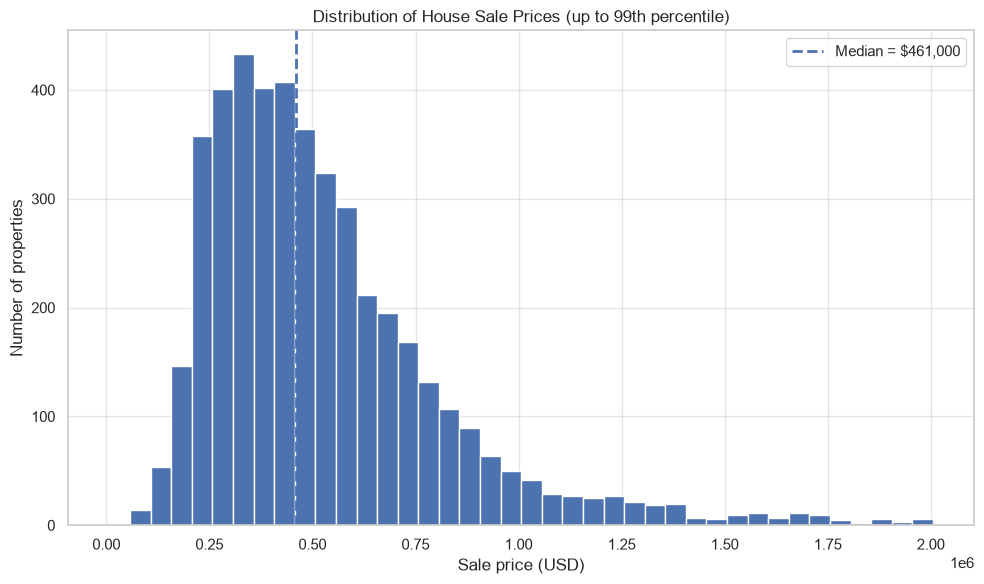

In [43]:
price_limit = clean_df["price"].quantile(0.99)
price_for_plot = clean_df.loc[
    clean_df["price"] <= price_limit,
    "price",
]

plt.figure(figsize=(10, 6))
plt.hist(price_for_plot, bins=40)
plt.axvline(
    price_for_plot.median(),
    linestyle="--",
    linewidth=2,
    label=f"Median = ${price_for_plot.median():,.0f}",
)
plt.title("Distribution of House Sale Prices (up to 99th percentile)")
plt.xlabel("Sale price (USD)")
plt.ylabel("Number of properties")
plt.legend()
finish_plot("univariate_01_price_distribution.png")


### Univariate 2 — Number of Bedrooms

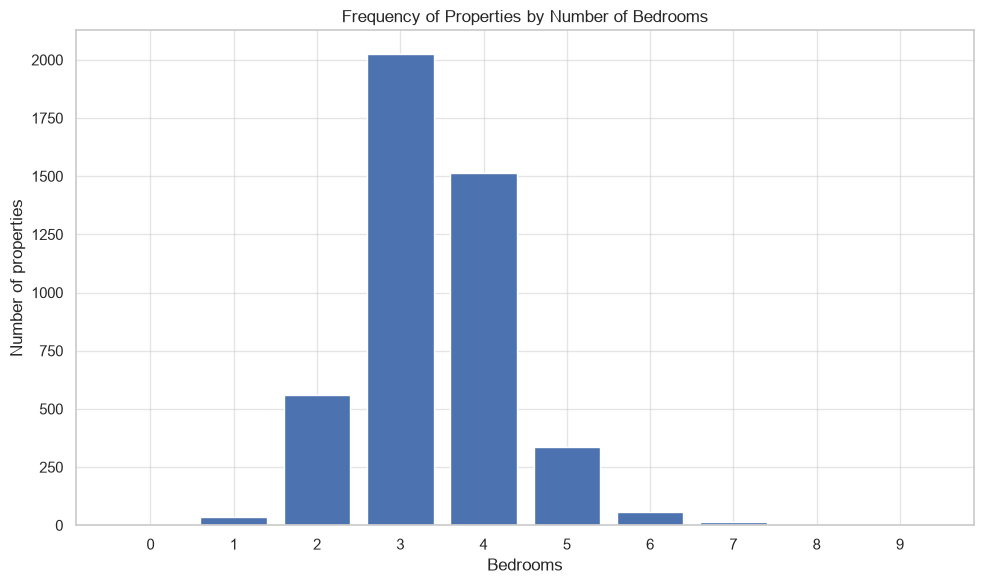

In [44]:
bedroom_counts = clean_df["bedrooms"].value_counts().sort_index()

plt.figure(figsize=(10, 6))
plt.bar(
    bedroom_counts.index.astype(str),
    bedroom_counts.values,
)
plt.title("Frequency of Properties by Number of Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Number of properties")
finish_plot("univariate_02_bedroom_counts.png")


### Univariate 3 — Living Area

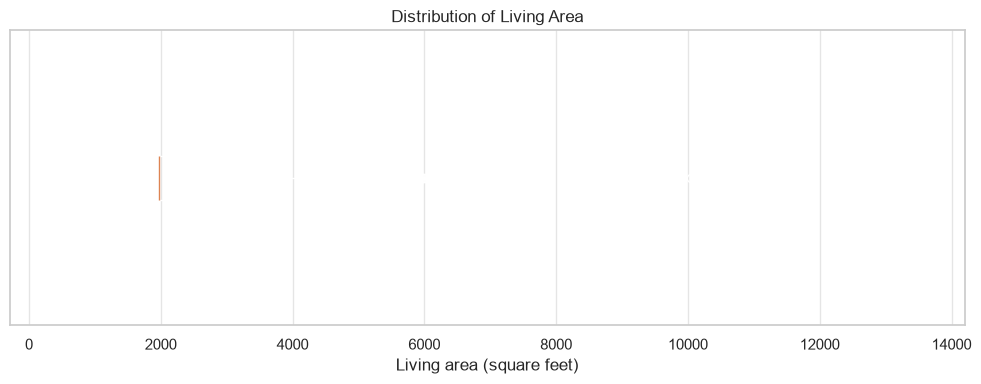

In [45]:
plt.figure(figsize=(10, 4))
plt.boxplot(
    clean_df["sqft_living"],
    vert=False,
    showfliers=True,
)
plt.title("Distribution of Living Area")
plt.xlabel("Living area (square feet)")
plt.yticks([])
finish_plot("univariate_03_living_area_boxplot.png")


### Univariate 4 — Most Common Cities

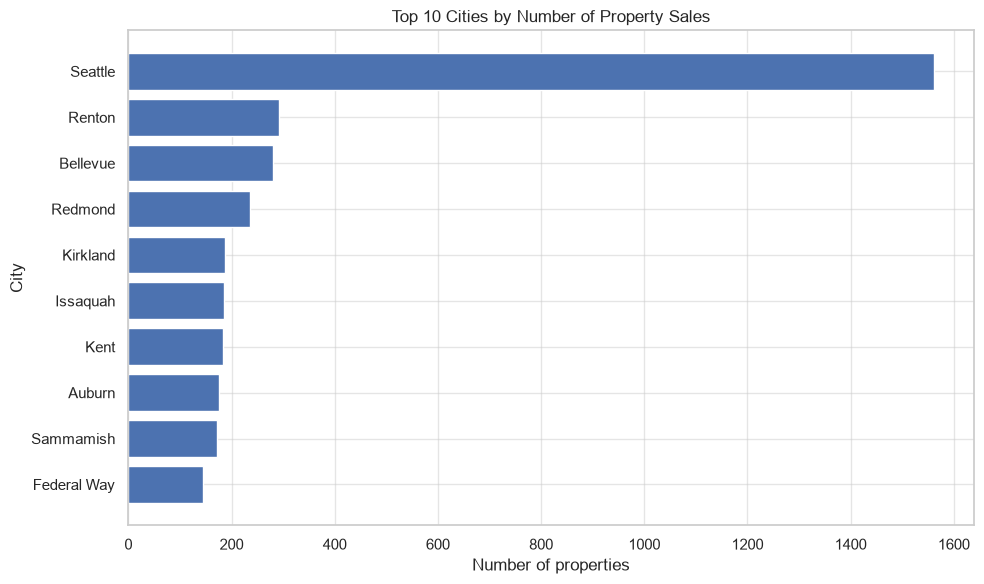

In [46]:
top_city_counts = clean_df["city"].value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(
    top_city_counts.index,
    top_city_counts.values,
)
plt.title("Top 10 Cities by Number of Property Sales")
plt.xlabel("Number of properties")
plt.ylabel("City")
finish_plot("univariate_04_top_cities.png")


# 9. Bivariate Analysis

Bivariate analysis examines the relationship between two variables. Four graphs are provided.


### Bivariate 1 — Living Area vs Sale Price

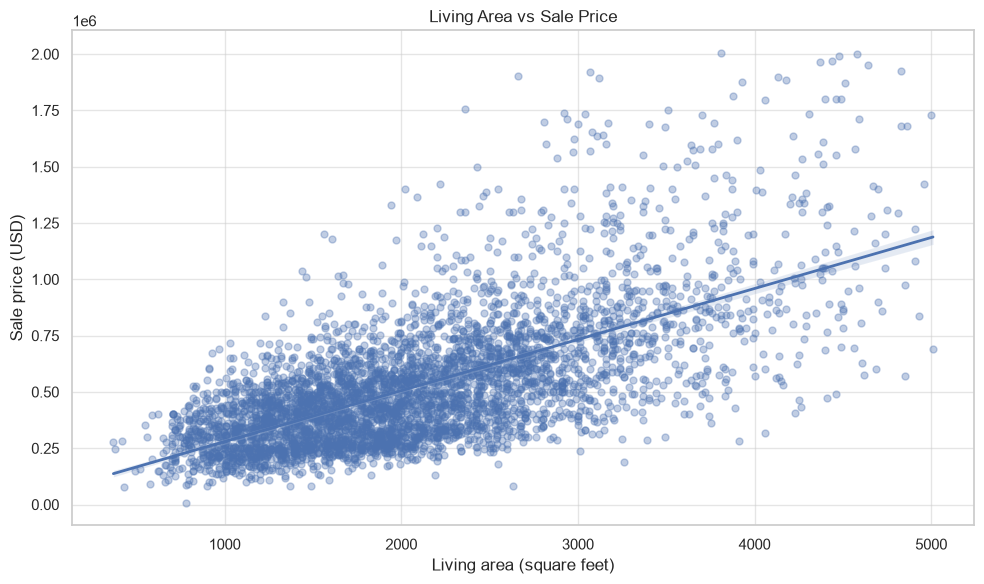

In [47]:
bivariate_scatter = clean_df.loc[
    (clean_df["price"] <= clean_df["price"].quantile(0.99))
    & (
        clean_df["sqft_living"]
        <= clean_df["sqft_living"].quantile(0.99)
    )
]

plt.figure(figsize=(10, 6))
sns.regplot(
    data=bivariate_scatter,
    x="sqft_living",
    y="price",
    scatter_kws={"alpha": 0.35, "s": 25},
    line_kws={"linewidth": 2},
)
plt.title("Living Area vs Sale Price")
plt.xlabel("Living area (square feet)")
plt.ylabel("Sale price (USD)")
finish_plot("bivariate_01_living_area_vs_price.png")


### Bivariate 2 — Bedroom Group vs Sale Price

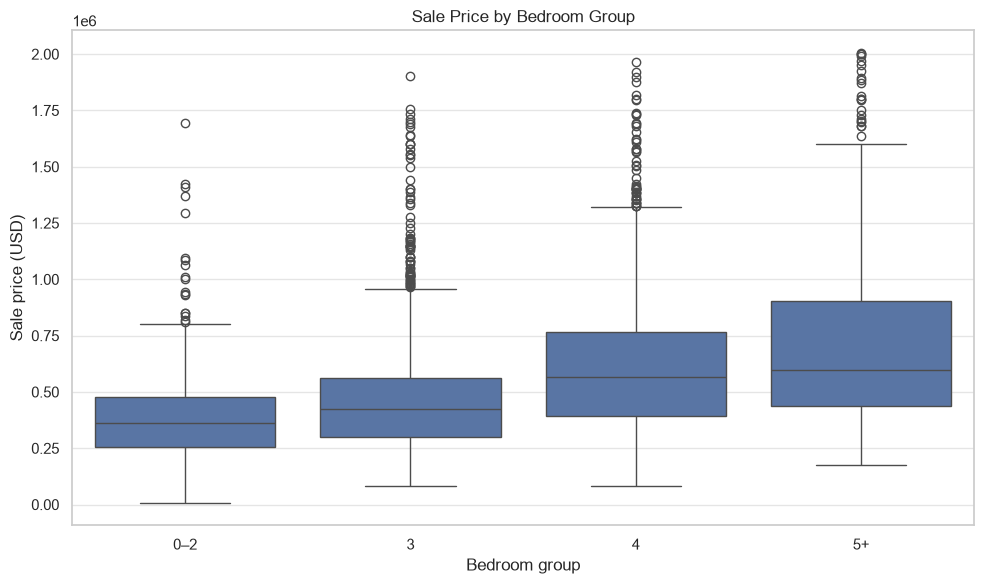

In [48]:
boxplot_data = clean_df.loc[
    clean_df["price"] <= clean_df["price"].quantile(0.99)
].copy()

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=boxplot_data,
    x="bedroom_group",
    y="price",
    order=["0–2", "3", "4", "5+"],
)
plt.title("Sale Price by Bedroom Group")
plt.xlabel("Bedroom group")
plt.ylabel("Sale price (USD)")
finish_plot("bivariate_02_bedroom_group_vs_price.png")


### Bivariate 3 — Median Price by City

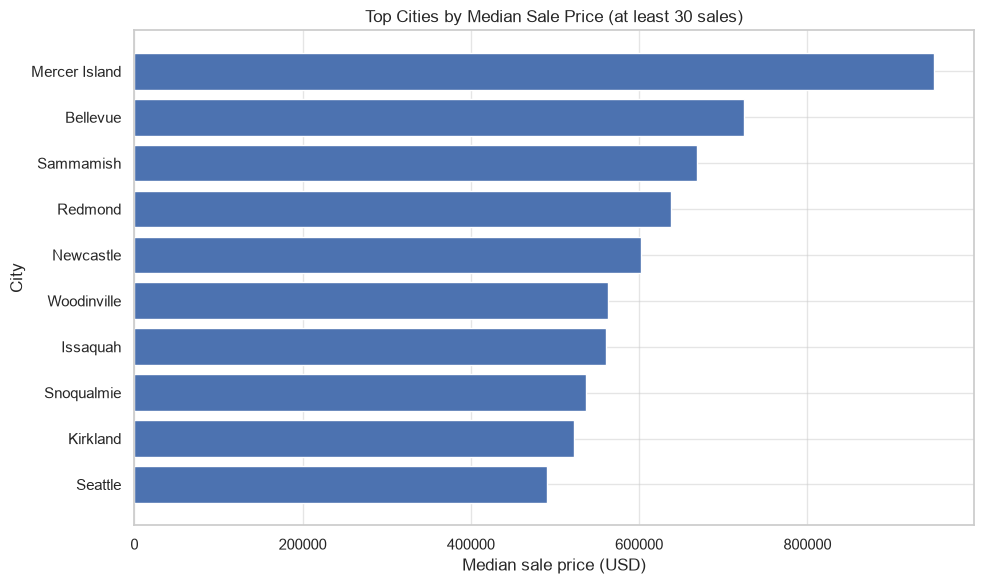

,median_price,sale_count
city,,
Mercer Island,"950,466.67",82
Bellevue,"725,000.00",281
Sammamish,"668,500.00",171
Redmond,"638,000.00",235
Newcastle,"602,500.00",33
Woodinville,"562,450.00",114
Issaquah,"561,000.00",186
Snoqualmie,"536,751.00",69
Kirkland,"522,000.00",187


In [49]:
city_statistics = (
    clean_df.groupby("city", observed=True)
    .agg(
        median_price=("price", "median"),
        sale_count=("price", "size"),
    )
    .query("sale_count >= 30")
    .nlargest(10, "median_price")
    .sort_values("median_price")
)

plt.figure(figsize=(10, 6))
plt.barh(
    city_statistics.index,
    city_statistics["median_price"],
)
plt.title("Top Cities by Median Sale Price (at least 30 sales)")
plt.xlabel("Median sale price (USD)")
plt.ylabel("City")
finish_plot("bivariate_03_city_vs_median_price.png")

display(city_statistics.sort_values("median_price", ascending=False))


### Bivariate 4 — Waterfront Status vs Sale Price

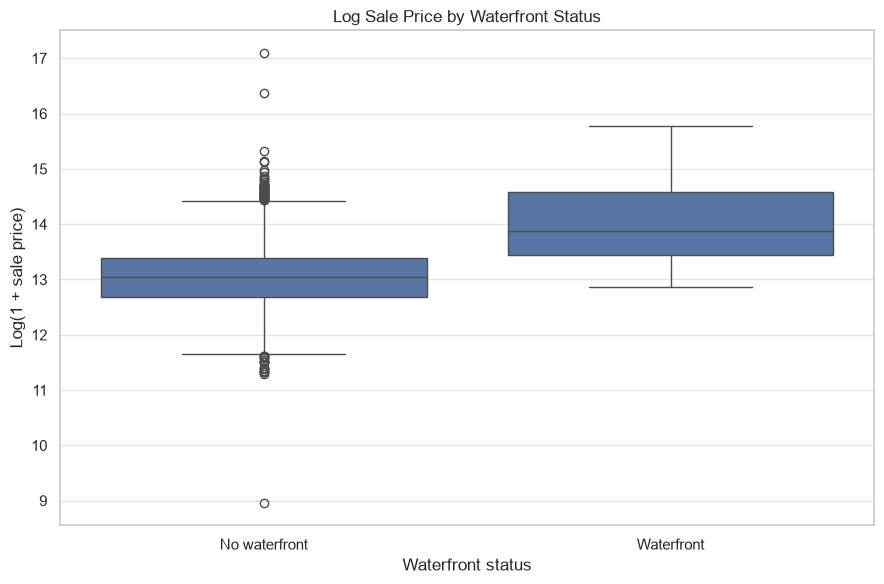

In [50]:
waterfront_plot = clean_df.assign(
    waterfront_label=clean_df["waterfront"].map({
        0: "No waterfront",
        1: "Waterfront",
    })
)

plt.figure(figsize=(9, 6))
sns.boxplot(
    data=waterfront_plot,
    x="waterfront_label",
    y="log_price",
)
plt.title("Log Sale Price by Waterfront Status")
plt.xlabel("Waterfront status")
plt.ylabel("Log(1 + sale price)")
finish_plot("bivariate_04_waterfront_vs_price.png")


# 10. Multivariate Analysis

Multivariate analysis examines three or more variables at the same time. Three graphs are provided.


### Multivariate 1 — Correlation Heatmap

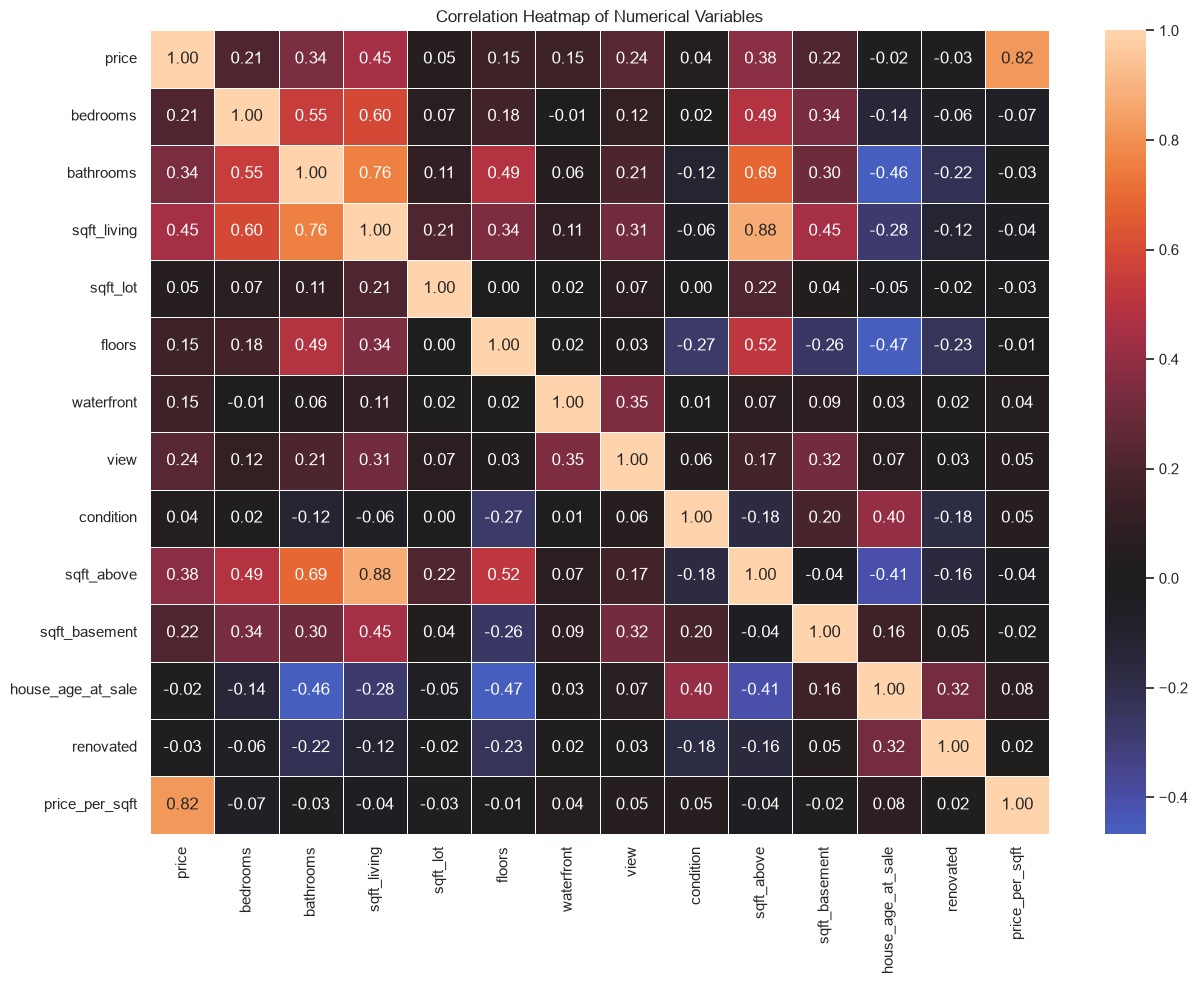

In [51]:
correlation_columns = [
    "price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot",
    "floors", "waterfront", "view", "condition", "sqft_above",
    "sqft_basement", "house_age_at_sale", "renovated",
    "price_per_sqft",
]

correlation_matrix = clean_df[correlation_columns].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    center=0,
    linewidths=0.4,
)
plt.title("Correlation Heatmap of Numerical Variables")
finish_plot("multivariate_01_correlation_heatmap.png")

correlation_matrix.to_csv(OUTPUT_DIR / "correlation_matrix.csv")


### Multivariate 2 — Price, Living Area, Condition, and Bathrooms

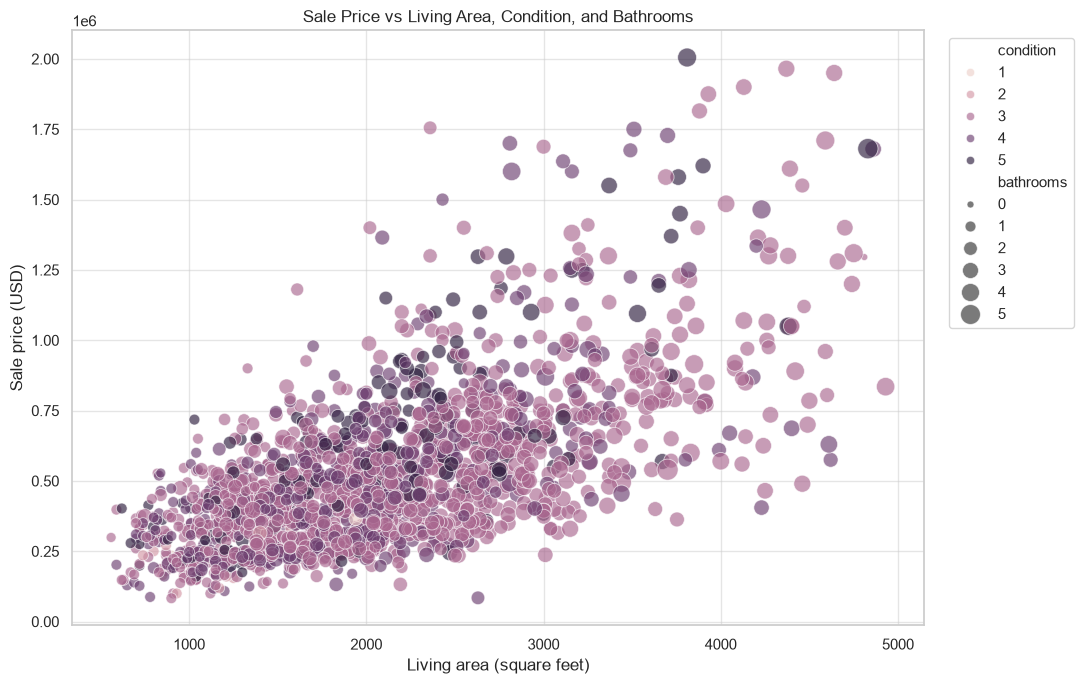

In [52]:
multivariate_scatter = clean_df.loc[
    (clean_df["price"] <= clean_df["price"].quantile(0.99))
    & (
        clean_df["sqft_living"]
        <= clean_df["sqft_living"].quantile(0.99)
    )
].copy()

if len(multivariate_scatter) > 1800:
    multivariate_scatter = multivariate_scatter.sample(
        1800,
        random_state=RANDOM_STATE,
    )

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=multivariate_scatter,
    x="sqft_living",
    y="price",
    hue="condition",
    size="bathrooms",
    sizes=(25, 230),
    alpha=0.65,
)
plt.title("Sale Price vs Living Area, Condition, and Bathrooms")
plt.xlabel("Living area (square feet)")
plt.ylabel("Sale price (USD)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
finish_plot("multivariate_02_price_area_condition_bathrooms.png")


### Multivariate 3 — Bedroom Count, Condition, and Median Price

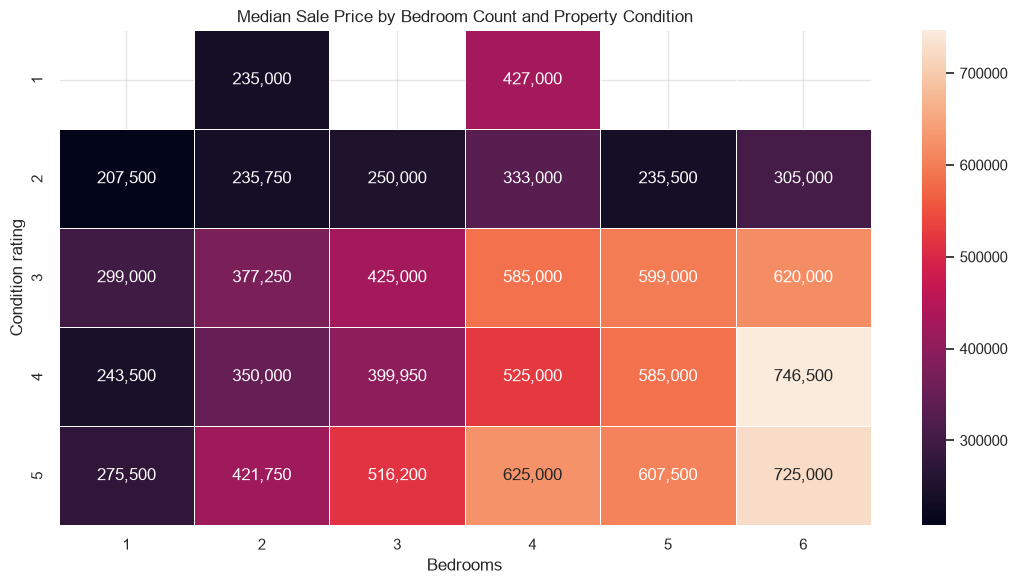

bedrooms,1,2,3,4,5,6
condition,,,,,,
1,NaN,"235,000.00",NaN,"427,000.00",NaN,NaN
2,"207,500.00","235,750.00","250,000.00","333,000.00","235,500.00","305,000.00"
3,"299,000.00","377,250.00","425,000.00","585,000.00","599,000.00","620,000.00"
4,"243,500.00","350,000.00","399,950.00","525,000.00","585,000.00","746,500.00"
5,"275,500.00","421,750.00","516,200.00","625,000.00","607,500.00","725,000.00"


In [53]:
bedroom_condition_prices = (
    clean_df.loc[clean_df["bedrooms"].between(1, 6)]
    .pivot_table(
        index="condition",
        columns="bedrooms",
        values="price",
        aggfunc="median",
        observed=True,
    )
)

plt.figure(figsize=(11, 6))
sns.heatmap(
    bedroom_condition_prices,
    annot=True,
    fmt=",.0f",
    linewidths=0.5,
)
plt.title("Median Sale Price by Bedroom Count and Property Condition")
plt.xlabel("Bedrooms")
plt.ylabel("Condition rating")
finish_plot("multivariate_03_bedrooms_condition_price.png")

display(bedroom_condition_prices)


## 11. Key Findings

The summary below is calculated dynamically from the cleaned data.


In [54]:
price_correlations = (
    clean_df.select_dtypes(include=np.number)
    .corr()["price"]
    .drop("price")
    .dropna()
    .sort_values(
        key=lambda series: series.abs(),
        ascending=False,
    )
)

eligible_cities = (
    clean_df.groupby("city", observed=True)
    .agg(
        median_price=("price", "median"),
        sale_count=("price", "size"),
    )
    .query("sale_count >= 30")
    .sort_values("median_price", ascending=False)
)

print("PHASE 1 SUMMARY")
print("=" * 70)
print(f"Rows retained after cleaning: {len(clean_df):,}")
print(f"Columns after transformation: {clean_df.shape[1]}")
print(f"Median sale price: ${clean_df['price'].median():,.0f}")
print(f"Mean sale price: ${clean_df['price'].mean():,.0f}")
print(
    "Median living area: "
    f"{clean_df['sqft_living'].median():,.0f} square feet"
)
print(
    "Most common bedroom count: "
    f"{int(clean_df['bedrooms'].mode().iloc[0])}"
)
print(
    "Strongest numerical association with price: "
    f"{price_correlations.index[0]} "
    f"(correlation = {price_correlations.iloc[0]:.3f})"
)

if not eligible_cities.empty:
    print(
        "Highest median-price city among cities with at least 30 sales: "
        f"{eligible_cities.index[0]} "
        f"(${eligible_cities.iloc[0]['median_price']:,.0f})"
    )

print(f"Waterfront properties: {int(clean_df['waterfront'].sum()):,}")
print(f"Renovated properties: {int(clean_df['renovated'].sum()):,}")

print("\nTop absolute correlations with sale price:")
display(price_correlations.head(10).to_frame("correlation_with_price"))


PHASE 1 SUMMARY
Rows retained after cleaning: 4,551
Columns after transformation: 32
Median sale price: $465,000
Mean sale price: $557,906
Median living area: 1,970 square feet
Most common bedroom count: 3
Strongest numerical association with price: price_per_sqft (correlation = 0.818)
Highest median-price city among cities with at least 30 sales: Mercer Island ($950,467)
Waterfront properties: 30
Renovated properties: 1,845

Top absolute correlations with sale price:


,correlation_with_price
price_per_sqft,0.82
log_price,0.68
sqft_living,0.45
sqft_above,0.38
bathrooms,0.34
view,0.24
sqft_basement,0.22
bedrooms,0.21
floors,0.15
waterfront,0.15


## 12. Final Validation and Output Inventory

In [55]:
validation_results = {
    "rows_after_cleaning": len(clean_df),
    "columns_after_transformation": clean_df.shape[1],
    "remaining_missing_cells": int(clean_df.isna().sum().sum()),
    "remaining_exact_duplicates": int(clean_df.duplicated().sum()),
    "non_positive_prices": int((clean_df["price"] <= 0).sum()),
    "univariate_visualizations": 4,
    "bivariate_visualizations": 4,
    "multivariate_visualizations": 3,
}

validation_df = pd.DataFrame.from_dict(
    validation_results,
    orient="index",
    columns=["value"],
)

display(validation_df)
validation_df.to_csv(OUTPUT_DIR / "validation_summary.csv")

assert validation_results["remaining_missing_cells"] == 0
assert validation_results["remaining_exact_duplicates"] == 0
assert validation_results["non_positive_prices"] == 0
assert validation_results["univariate_visualizations"] >= 3
assert validation_results["bivariate_visualizations"] >= 3
assert validation_results["multivariate_visualizations"] >= 3

print("All Phase 1 validation checks passed.")

print("\nCreated files:")
for output_file in sorted(OUTPUT_DIR.rglob("*")):
    if output_file.is_file():
        print(f"- {output_file}")


,value
rows_after_cleaning,4551
columns_after_transformation,32
remaining_missing_cells,0
remaining_exact_duplicates,0
non_positive_prices,0
univariate_visualizations,4
bivariate_visualizations,4
multivariate_visualizations,3


All Phase 1 validation checks passed.

Created files:
- phase1_outputs\additional_statistics_before_cleaning.csv
- phase1_outputs\categorical_summary_after_cleaning.csv
- phase1_outputs\categorical_summary_before_cleaning.csv
- phase1_outputs\cleaning_log.csv
- phase1_outputs\correlation_matrix.csv
- phase1_outputs\figures\bivariate_01_living_area_vs_price.png
- phase1_outputs\figures\bivariate_02_bedroom_group_vs_price.png
- phase1_outputs\figures\bivariate_03_city_vs_median_price.png
- phase1_outputs\figures\bivariate_04_waterfront_vs_price.png
- phase1_outputs\figures\multivariate_01_correlation_heatmap.png
- phase1_outputs\figures\multivariate_02_price_area_condition_bathrooms.png
- phase1_outputs\figures\multivariate_03_bedrooms_condition_price.png
- phase1_outputs\figures\univariate_01_price_distribution.png
- phase1_outputs\figures\univariate_02_bedroom_counts.png
- phase1_outputs\figures\univariate_03_living_area_boxplot.png
- phase1_outputs\figures\univariate_04_top_cities.png

In [56]:

# PHASE II — Exploratory Data Analysis
# 1D, 2D, 3D Statistical Analysis + Clustering


from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    mean_squared_error,
    mean_absolute_error
)
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid")

# Output folders
PHASE2_DIR = Path("phase2_outputs")
FIG_DIR = PHASE2_DIR / "figures"

PHASE2_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# Load the cleaned and transformed dataset produced in Phase I
DATA_PATH = Path("phase1_outputs/house_price_cleaned_transformed.csv")

phase2_df = pd.read_csv(DATA_PATH)

if "date" in phase2_df.columns:
    phase2_df["date"] = pd.to_datetime(phase2_df["date"], errors="coerce")

print("Phase II dataset loaded successfully.")
print("Shape:", phase2_df.shape)
print("\nColumns:")
print(phase2_df.columns.tolist())

display(phase2_df.head())

Phase II dataset loaded successfully.
Shape: (4551, 32)

Columns:
['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city', 'statezip', 'country', 'sale_year', 'sale_month', 'sale_month_name', 'sale_quarter', 'house_age_at_sale', 'renovated', 'years_since_renovation', 'price_per_sqft', 'living_to_lot_ratio', 'has_basement', 'log_price', 'log_sqft_lot', 'bedroom_group', 'price_category']


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country,sale_year,sale_month,sale_month_name,sale_quarter,house_age_at_sale,renovated,years_since_renovation,price_per_sqft,living_to_lot_ratio,has_basement,log_price,log_sqft_lot,bedroom_group,price_category
0,2014-05-02,"313,000.00",3,1.50,1340,7912,1.50,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA,2014,5,May,2014Q2,59,1,9,233.58,0.17,0,12.65,8.98,3,Low
1,2014-05-02,"2,384,000.00",5,2.50,3650,9050,2.00,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA,2014,5,May,2014Q2,93,0,0,653.15,0.40,1,14.68,9.11,5+,High
2,2014-05-02,"342,000.00",3,2.00,1930,11947,1.00,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA,2014,5,May,2014Q2,48,0,0,177.20,0.16,0,12.74,9.39,3,Lower-middle
3,2014-05-02,"420,000.00",3,2.25,2000,8030,1.00,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA,2014,5,May,2014Q2,51,0,0,210.00,0.25,1,12.95,8.99,3,Lower-middle
4,2014-05-02,"550,000.00",4,2.50,1940,10500,1.00,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA,2014,5,May,2014Q2,38,1,22,283.51,0.18,1,13.22,9.26,4,Upper-middle


1D Numerical Statistical Analysis


,count,missing,mean,median,mode,minimum,maximum,range,variance,std_dev,q1,q3,iqr,skewness,kurtosis,coefficient_of_variation_percent
variable,,,,,,,,,,,,,,,,
price,4551,0,"557,905.90","465,000.00","300,000.00","7,800.00","26,590,000.00","26,582,200.00","318,016,899,720.59","563,929.87","326,264.29","657,500.00","331,235.71",25.02,"1,053.87",101.08
bedrooms,4551,0,3.39,3.00,3.00,0.00,9.00,9.00,0.82,0.90,3.00,4.00,1.00,0.47,1.29,26.65
bathrooms,4551,0,2.15,2.25,2.50,0.00,8.00,8.00,0.60,0.78,1.75,2.50,0.75,0.59,1.81,36.03
sqft_living,4551,0,"2,132.37","1,970.00","1,720.00",370.00,"13,540.00","13,170.00","913,839.84",955.95,"1,460.00","2,610.00","1,150.00",1.72,8.41,44.83
sqft_lot,4551,0,"14,835.28","7,680.00","5,000.00",638.00,"1,074,218.00","1,073,580.00","1,293,414,893.80","35,964.08","5,000.00","10,978.00","5,978.00",11.33,220.19,242.42
floors,4551,0,1.51,1.50,1.00,1.00,3.50,2.50,0.29,0.54,1.00,2.00,1.00,0.55,-0.54,35.61
waterfront,4551,0,0.01,0.00,0.00,0.00,1.00,1.00,0.01,0.08,0.00,0.00,0.00,12.20,146.87,"1,227.73"
view,4551,0,0.23,0.00,0.00,0.00,4.00,4.00,0.59,0.77,0.00,0.00,0.00,3.37,10.71,326.14
condition,4551,0,3.45,3.00,3.00,1.00,5.00,4.00,0.46,0.68,3.00,4.00,1.00,0.96,0.22,19.57



1D Categorical Statistical Analysis


,count,missing,unique_values,mode,mode_frequency
variable,,,,,
street,4551,0,4476,2520 Mulberry Walk NE,4
city,4551,0,44,Seattle,1561
statezip,4551,0,77,WA 98103,148
country,4551,0,1,USA,4551
sale_month_name,4551,0,3,June,2155
sale_quarter,4551,0,2,2014Q2,3903
bedroom_group,4551,0,4,3,2025
price_category,4551,0,4,Lower-middle,1148


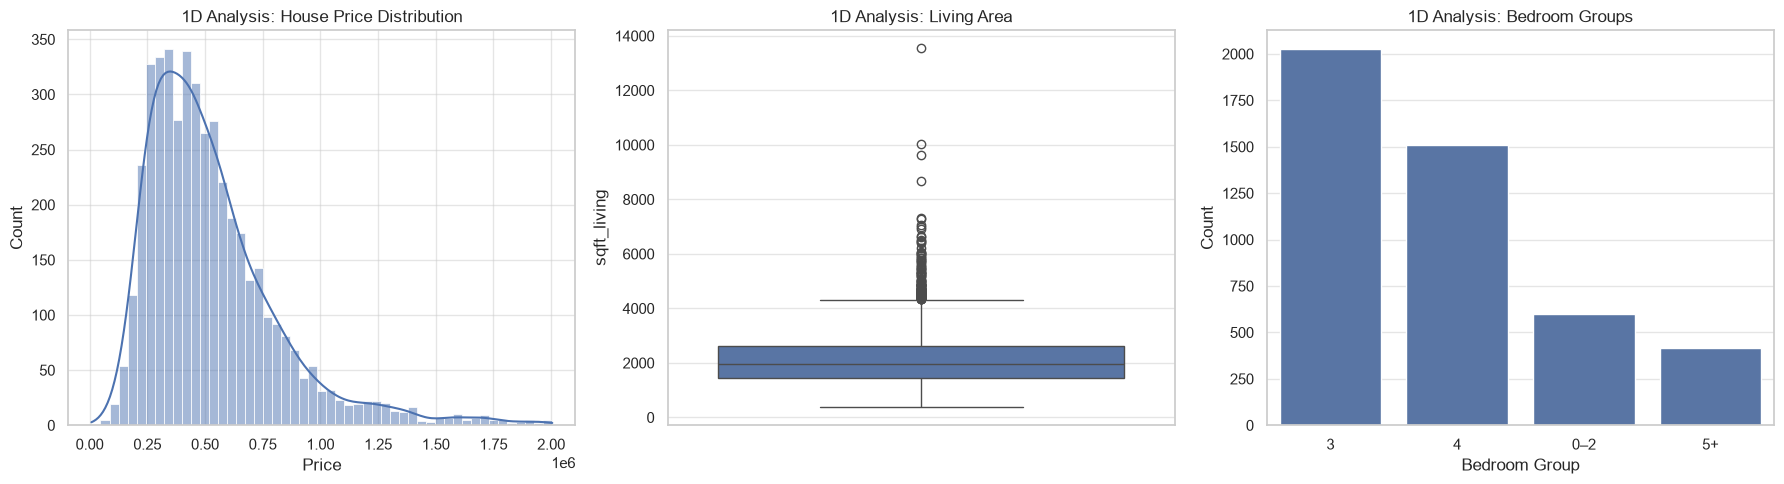

1D statistical analysis completed.


In [57]:

# 1D STATISTICAL ANALYSIS


numeric_cols = phase2_df.select_dtypes(include=np.number).columns.tolist()

one_d_rows = []

for col in numeric_cols:
    s = (
        pd.to_numeric(phase2_df[col], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    mode_values = s.mode()
    mean_value = s.mean()

    one_d_rows.append({
        "variable": col,
        "count": s.count(),
        "missing": phase2_df[col].isna().sum(),
        "mean": mean_value,
        "median": s.median(),
        "mode": mode_values.iloc[0] if len(mode_values) else np.nan,
        "minimum": s.min(),
        "maximum": s.max(),
        "range": s.max() - s.min(),
        "variance": s.var(ddof=1),
        "std_dev": s.std(ddof=1),
        "q1": s.quantile(0.25),
        "q3": s.quantile(0.75),
        "iqr": s.quantile(0.75) - s.quantile(0.25),
        "skewness": s.skew(),
        "kurtosis": s.kurt(),
        "coefficient_of_variation_percent":
            (s.std(ddof=1) / mean_value * 100)
            if mean_value != 0 else np.nan
    })

one_d_numeric = pd.DataFrame(one_d_rows).set_index("variable")

print("1D Numerical Statistical Analysis")
display(one_d_numeric.round(4))

one_d_numeric.to_csv(
    PHASE2_DIR / "1d_numerical_statistics.csv"
)



# Categorical 1D statistics


categorical_cols = phase2_df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

one_d_cat_rows = []

for col in categorical_cols:
    s = phase2_df[col]
    mode_values = s.mode(dropna=True)

    one_d_cat_rows.append({
        "variable": col,
        "count": s.count(),
        "missing": s.isna().sum(),
        "unique_values": s.nunique(dropna=True),
        "mode": mode_values.iloc[0] if len(mode_values) else np.nan,
        "mode_frequency":
            s.value_counts(dropna=True).iloc[0]
            if s.count() > 0 else 0
    })

one_d_categorical = pd.DataFrame(one_d_cat_rows).set_index("variable")

print("\n1D Categorical Statistical Analysis")
display(one_d_categorical)

one_d_categorical.to_csv(
    PHASE2_DIR / "1d_categorical_statistics.csv"
)



# 1D visualizations


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Price histogram - 99th percentile used only for readable plotting
price_limit = phase2_df["price"].quantile(0.99)
price_plot_df = phase2_df[phase2_df["price"] <= price_limit]

sns.histplot(
    data=price_plot_df,
    x="price",
    kde=True,
    ax=axes[0]
)
axes[0].set_title("1D Analysis: House Price Distribution")
axes[0].set_xlabel("Price")

sns.boxplot(
    data=phase2_df,
    y="sqft_living",
    ax=axes[1]
)
axes[1].set_title("1D Analysis: Living Area")

bedroom_counts = phase2_df["bedroom_group"].value_counts()

sns.barplot(
    x=bedroom_counts.index,
    y=bedroom_counts.values,
    ax=axes[2]
)
axes[2].set_title("1D Analysis: Bedroom Groups")
axes[2].set_xlabel("Bedroom Group")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "1d_statistical_analysis.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("1D statistical analysis completed.")

Pearson Correlation Matrix


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,sale_month,house_age_at_sale,renovated,years_since_renovation,price_per_sqft,living_to_lot_ratio,has_basement,log_price,log_sqft_lot
price,1.00,0.21,0.34,0.45,0.05,0.15,0.15,0.24,0.04,0.38,0.22,0.02,-0.03,0.04,-0.02,-0.03,-0.01,0.82,0.07,0.11,0.68,0.10
bedrooms,0.21,1.00,0.55,0.60,0.07,0.18,-0.01,0.12,0.02,0.49,0.34,0.14,-0.06,0.01,-0.14,-0.06,-0.02,-0.07,0.01,0.18,0.35,0.22
bathrooms,0.34,0.55,1.00,0.76,0.11,0.49,0.06,0.21,-0.12,0.69,0.30,0.46,-0.22,0.03,-0.46,-0.22,-0.07,-0.03,0.27,0.16,0.55,0.13
sqft_living,0.45,0.60,0.76,1.00,0.21,0.34,0.11,0.31,-0.06,0.88,0.45,0.28,-0.12,0.03,-0.28,-0.12,-0.04,-0.04,0.05,0.20,0.67,0.37
sqft_lot,0.05,0.07,0.11,0.21,1.00,0.00,0.02,0.07,0.00,0.22,0.04,0.05,-0.02,-0.02,-0.05,-0.02,-0.04,-0.03,-0.29,-0.03,0.09,0.66
floors,0.15,0.18,0.49,0.34,0.00,1.00,0.02,0.03,-0.27,0.52,-0.26,0.47,-0.24,0.04,-0.47,-0.23,-0.04,-0.01,0.54,-0.27,0.30,-0.21
waterfront,0.15,-0.01,0.06,0.11,0.02,0.02,1.00,0.35,0.01,0.07,0.09,-0.03,0.02,0.00,0.03,0.02,0.00,0.04,-0.03,0.03,0.14,0.07
view,0.24,0.12,0.21,0.31,0.07,0.03,0.35,1.00,0.06,0.17,0.32,-0.07,0.03,-0.01,0.07,0.03,0.01,0.05,0.02,0.20,0.32,0.12
condition,0.04,0.02,-0.12,-0.06,0.00,-0.27,0.01,0.06,1.00,-0.18,0.20,-0.40,-0.18,0.02,0.40,-0.18,-0.02,0.05,-0.15,0.17,0.06,0.06
sqft_above,0.38,0.49,0.69,0.88,0.22,0.52,0.07,0.17,-0.18,1.00,-0.04,0.41,-0.16,0.04,-0.41,-0.16,-0.04,-0.04,0.02,-0.22,0.58,0.37



Pairwise Statistical Relationships with Price


,variable_x,variable_y,pearson_r,pearson_p_value,spearman_rho,spearman_p_value,regression_slope,regression_intercept,r_squared,regression_p_value,slope_std_error
2,sqft_living,price,0.45,0.00,0.66,0.00,262.80,"-2,489.61",0.20,0.00,7.83
8,sqft_above,price,0.38,0.00,0.55,0.00,251.23,"100,105.14",0.14,0.00,9.05
1,bathrooms,price,0.34,0.00,0.51,0.00,"247,788.69","23,916.10",0.12,0.00,"10,123.83"
6,view,price,0.24,0.00,0.29,0.00,"178,739.49","515,960.44",0.06,0.00,"10,598.00"
9,sqft_basement,price,0.22,0.00,0.25,0.00,265.84,"475,456.04",0.05,0.00,17.66
0,bedrooms,price,0.21,0.00,0.36,0.00,"131,057.12","113,014.34",0.04,0.00,"9,036.44"
4,floors,price,0.15,0.00,0.33,0.00,"159,962.76","316,010.99",0.02,0.00,"15,343.66"
5,waterfront,price,0.15,0.00,0.10,0.00,"1,045,771.11","551,012.22",0.02,0.00,"102,141.27"
17,has_basement,price,0.11,0.00,0.19,0.00,"129,793.42","505,629.18",0.01,0.00,"16,936.94"
18,log_sqft_lot,price,0.10,0.00,0.08,0.00,"63,317.41","-11,900.38",0.01,0.00,"9,122.31"



Chi-Square / Cramer's V Results


,variable_1,variable_2,chi_square,degrees_of_freedom,p_value,cramers_v
0,bedroom_group,price_category,545.90,9,0.00,0.20
1,condition,price_category,108.78,12,0.00,0.09
2,waterfront,price_category,44.77,3,0.00,0.10
3,city,price_category,"2,287.68",129,0.00,0.41


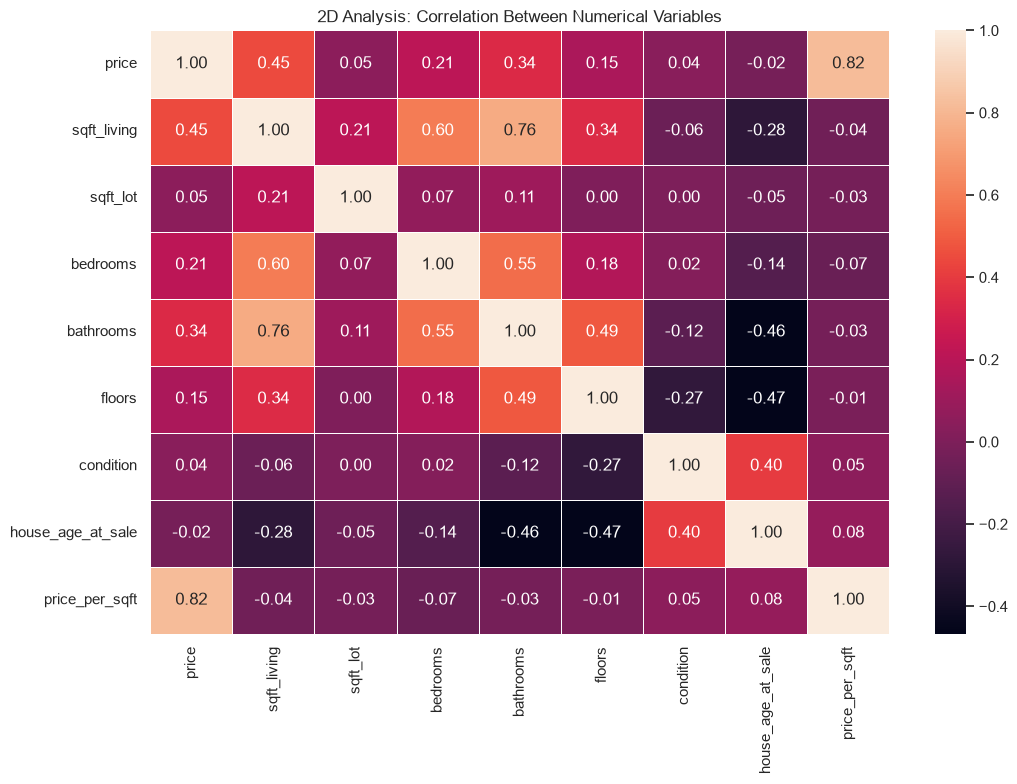

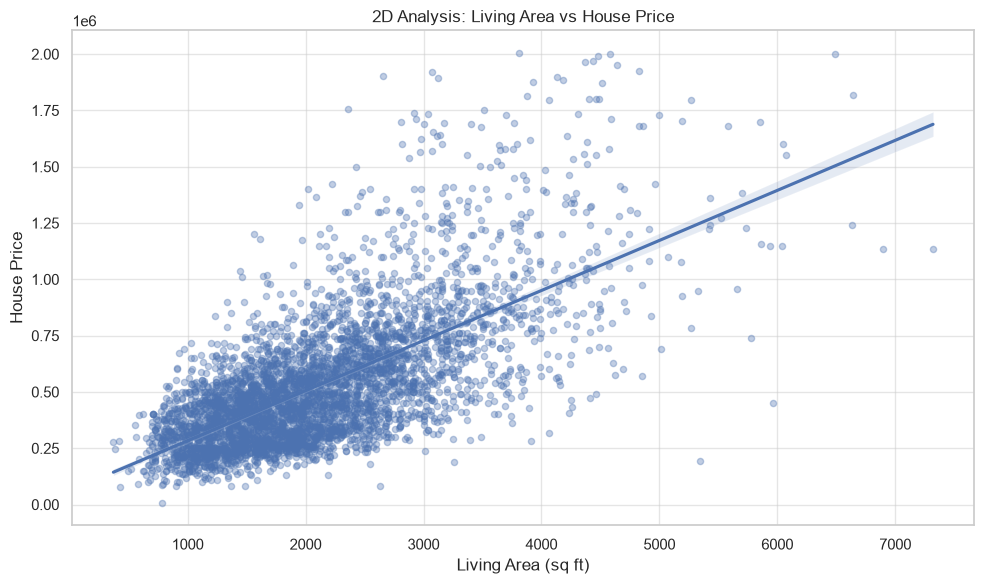

2D statistical analysis completed.


In [58]:

# 2D STATISTICAL ANALYSIS


valid_numeric_cols = [
    col for col in numeric_cols
    if phase2_df[col].nunique(dropna=True) > 1
]


# Covariance and correlation matrices


covariance_matrix = phase2_df[valid_numeric_cols].cov()

pearson_matrix = phase2_df[valid_numeric_cols].corr(
    method="pearson"
)

spearman_matrix = phase2_df[valid_numeric_cols].corr(
    method="spearman"
)

covariance_matrix.to_csv(
    PHASE2_DIR / "2d_covariance_matrix.csv"
)

pearson_matrix.to_csv(
    PHASE2_DIR / "2d_pearson_correlation_matrix.csv"
)

spearman_matrix.to_csv(
    PHASE2_DIR / "2d_spearman_correlation_matrix.csv"
)

print("Pearson Correlation Matrix")
display(pearson_matrix.round(3))



# Price vs every independent numerical variable


# Derived variables containing price itself are excluded here
# because they would create an artificial relationship.
exclude_target_derived = {
    "price",
    "log_price",
    "price_per_sqft"
}

pair_rows = []

for col in valid_numeric_cols:

    if col in exclude_target_derived:
        continue

    pair = (
        phase2_df[["price", col]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if len(pair) < 3 or pair[col].nunique() < 2:
        continue

    pearson_r, pearson_p = stats.pearsonr(
        pair[col],
        pair["price"]
    )

    spearman_r, spearman_p = stats.spearmanr(
        pair[col],
        pair["price"]
    )

    regression = stats.linregress(
        pair[col],
        pair["price"]
    )

    pair_rows.append({
        "variable_x": col,
        "variable_y": "price",
        "pearson_r": pearson_r,
        "pearson_p_value": pearson_p,
        "spearman_rho": spearman_r,
        "spearman_p_value": spearman_p,
        "regression_slope": regression.slope,
        "regression_intercept": regression.intercept,
        "r_squared": regression.rvalue ** 2,
        "regression_p_value": regression.pvalue,
        "slope_std_error": regression.stderr
    })

pairwise_price_stats = pd.DataFrame(pair_rows)

pairwise_price_stats = pairwise_price_stats.sort_values(
    "pearson_r",
    key=lambda x: x.abs(),
    ascending=False
)

print("\nPairwise Statistical Relationships with Price")
display(pairwise_price_stats.round(5))

pairwise_price_stats.to_csv(
    PHASE2_DIR / "2d_price_pairwise_statistics.csv",
    index=False
)



# Numerical variable grouped by categorical/discrete variable


group_variables = [
    "bedroom_group",
    "condition",
    "waterfront",
    "renovated",
    "has_basement",
    "city"
]

for col in group_variables:

    if col not in phase2_df.columns:
        continue

    grouped = (
        phase2_df
        .groupby(col, observed=True)["price"]
        .agg([
            "count",
            "mean",
            "median",
            "std",
            "min",
            "max"
        ])
        .sort_values("mean", ascending=False)
    )

    grouped.to_csv(
        PHASE2_DIR / f"2d_price_by_{col}.csv"
    )



# Categorical vs categorical:
# Chi-square test and Cramer's V


categorical_pairs = [
    ("bedroom_group", "price_category"),
    ("condition", "price_category"),
    ("waterfront", "price_category"),
    ("city", "price_category")
]

chi_square_results = []

for col1, col2 in categorical_pairs:

    if col1 not in phase2_df.columns or col2 not in phase2_df.columns:
        continue

    table = pd.crosstab(
        phase2_df[col1],
        phase2_df[col2]
    )

    chi2, p_value, dof, expected = stats.chi2_contingency(table)

    n = table.to_numpy().sum()
    min_dimension = min(table.shape[0] - 1, table.shape[1] - 1)

    cramers_v = (
        np.sqrt(chi2 / (n * min_dimension))
        if min_dimension > 0
        else np.nan
    )

    chi_square_results.append({
        "variable_1": col1,
        "variable_2": col2,
        "chi_square": chi2,
        "degrees_of_freedom": dof,
        "p_value": p_value,
        "cramers_v": cramers_v
    })

chi_square_results = pd.DataFrame(chi_square_results)

print("\nChi-Square / Cramer's V Results")
display(chi_square_results.round(5))

chi_square_results.to_csv(
    PHASE2_DIR / "2d_categorical_association_tests.csv",
    index=False
)



# 2D visualizations


selected_corr_cols = [
    "price",
    "sqft_living",
    "sqft_lot",
    "bedrooms",
    "bathrooms",
    "floors",
    "condition",
    "house_age_at_sale",
    "price_per_sqft"
]

selected_corr_cols = [
    c for c in selected_corr_cols
    if c in phase2_df.columns
]

plt.figure(figsize=(11, 8))

sns.heatmap(
    phase2_df[selected_corr_cols].corr(),
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title("2D Analysis: Correlation Between Numerical Variables")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "2d_correlation_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


# Scatter plot
plot_2d = phase2_df[
    phase2_df["price"] <= phase2_df["price"].quantile(0.99)
]

plt.figure(figsize=(10, 6))

sns.regplot(
    data=plot_2d,
    x="sqft_living",
    y="price",
    scatter_kws={
        "alpha": 0.35,
        "s": 20
    }
)

plt.title("2D Analysis: Living Area vs House Price")
plt.xlabel("Living Area (sq ft)")
plt.ylabel("House Price")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "2d_living_area_vs_price.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("2D statistical analysis completed.")

Multiple Regression — Three Variable Analysis


,model,observations,intercept,r_squared,rmse,mae,coefficient_sqft_living,coefficient_bathrooms,coefficient_house_age_at_sale,coefficient_condition
0,price ~ sqft_living + bathrooms,4551,"-7,937.11",0.20,"504,811.91","182,312.17",258.83,"6,456.58",NaN,NaN
1,price ~ sqft_living + house_age_at_sale,4551,"-137,077.03",0.21,"501,023.57","176,184.95",282.01,NaN,"2,167.06",NaN
2,price ~ sqft_living + condition,4551,"-200,821.39",0.20,"503,412.03","181,191.51",265.28,NaN,NaN,"55,970.24"



Partial Correlation Results


,variable_x,variable_y,controlled_variable,partial_correlation,p_value
0,price,sqft_living,bathrooms,0.30,0.00
1,price,sqft_living,condition,0.45,0.00
2,price,sqft_living,house_age_at_sale,0.46,0.00
3,price,bathrooms,sqft_living,0.01,0.66


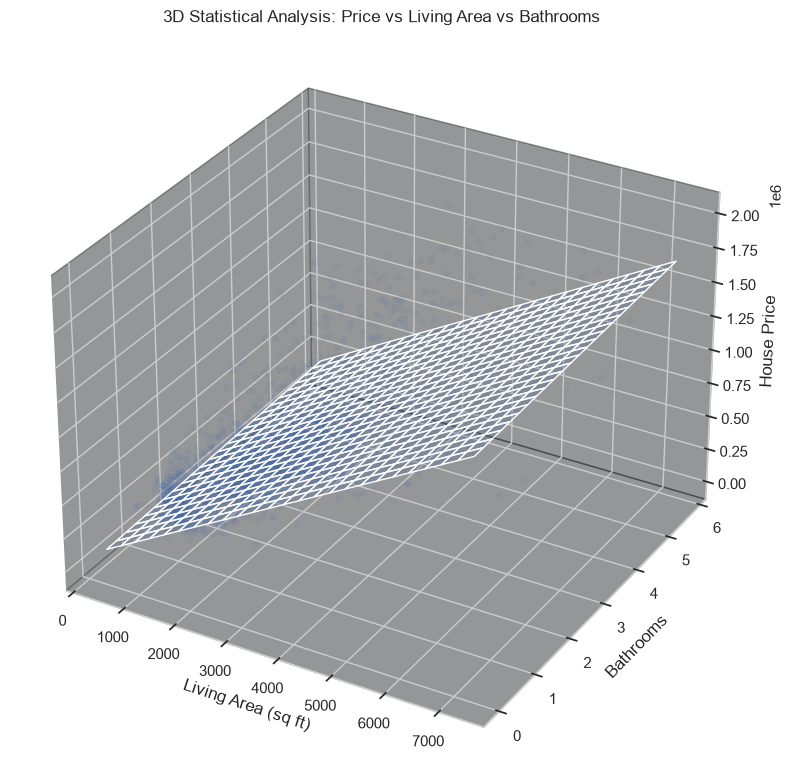

3D statistical analysis completed.


In [59]:

# 3D STATISTICAL ANALYSIS


# Three variables:
# dependent variable + two independent variables

models_3d = {
    "price ~ sqft_living + bathrooms":
        ["sqft_living", "bathrooms"],

    "price ~ sqft_living + house_age_at_sale":
        ["sqft_living", "house_age_at_sale"],

    "price ~ sqft_living + condition":
        ["sqft_living", "condition"]
}

three_d_rows = []

for model_name, predictors in models_3d.items():

    subset = (
        phase2_df[predictors + ["price"]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    X = subset[predictors]
    y = subset["price"]

    model = LinearRegression()
    model.fit(X, y)

    predictions = model.predict(X)

    result = {
        "model": model_name,
        "observations": len(subset),
        "intercept": model.intercept_,
        "r_squared": model.score(X, y),
        "rmse": np.sqrt(
            mean_squared_error(y, predictions)
        ),
        "mae": mean_absolute_error(
            y,
            predictions
        )
    }

    for predictor, coefficient in zip(
        predictors,
        model.coef_
    ):
        result[f"coefficient_{predictor}"] = coefficient

    three_d_rows.append(result)

three_d_regression = pd.DataFrame(three_d_rows)

print("Multiple Regression — Three Variable Analysis")
display(three_d_regression.round(4))

three_d_regression.to_csv(
    PHASE2_DIR / "3d_multiple_regression_results.csv",
    index=False
)



# Partial correlations
# Relationship between X and Y while controlling Z


def partial_correlation(data, x, y, control):

    subset = (
        data[[x, y, control]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    control_values = subset[[control]]

    model_x = LinearRegression().fit(
        control_values,
        subset[x]
    )

    model_y = LinearRegression().fit(
        control_values,
        subset[y]
    )

    residual_x = (
        subset[x]
        - model_x.predict(control_values)
    )

    residual_y = (
        subset[y]
        - model_y.predict(control_values)
    )

    r, p = stats.pearsonr(
        residual_x,
        residual_y
    )

    return r, p


partial_tests = [
    ("price", "sqft_living", "bathrooms"),
    ("price", "sqft_living", "condition"),
    ("price", "sqft_living", "house_age_at_sale"),
    ("price", "bathrooms", "sqft_living")
]

partial_rows = []

for x, y, control in partial_tests:

    r, p = partial_correlation(
        phase2_df,
        x,
        y,
        control
    )

    partial_rows.append({
        "variable_x": x,
        "variable_y": y,
        "controlled_variable": control,
        "partial_correlation": r,
        "p_value": p
    })

partial_results = pd.DataFrame(partial_rows)

print("\nPartial Correlation Results")
display(partial_results.round(5))

partial_results.to_csv(
    PHASE2_DIR / "3d_partial_correlations.csv",
    index=False
)


# Actual 3D scatter plot + regression plane


plot_3d = phase2_df[
    phase2_df["price"]
    <= phase2_df["price"].quantile(0.99)
][[
    "sqft_living",
    "bathrooms",
    "price"
]].dropna()

X_plot = plot_3d[[
    "sqft_living",
    "bathrooms"
]]

y_plot = plot_3d["price"]

plane_model = LinearRegression()
plane_model.fit(X_plot, y_plot)

x_range = np.linspace(
    X_plot["sqft_living"].min(),
    X_plot["sqft_living"].max(),
    25
)

y_range = np.linspace(
    X_plot["bathrooms"].min(),
    X_plot["bathrooms"].max(),
    25
)

xx, yy = np.meshgrid(
    x_range,
    y_range
)

grid = np.column_stack([
    xx.ravel(),
    yy.ravel()
])

zz = plane_model.predict(grid).reshape(xx.shape)


fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(
    111,
    projection="3d"
)

ax.scatter(
    plot_3d["sqft_living"],
    plot_3d["bathrooms"],
    plot_3d["price"],
    alpha=0.3,
    s=15
)

ax.plot_surface(
    xx,
    yy,
    zz,
    alpha=0.25
)

ax.set_xlabel("Living Area (sq ft)")
ax.set_ylabel("Bathrooms")
ax.set_zlabel("House Price")

ax.set_title(
    "3D Statistical Analysis: "
    "Price vs Living Area vs Bathrooms"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "3d_price_living_area_bathrooms.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("3D statistical analysis completed.")

K-Means Model Selection


,k,inertia,silhouette_score
0,2,"23,532.66",0.24
1,3,"19,970.98",0.20
2,4,"17,484.34",0.21
3,5,"16,115.74",0.18
4,6,"14,947.11",0.19
5,7,"13,812.80",0.20
6,8,"13,035.96",0.18


Selected number of clusters: 2

K-Means Cluster Profiles


,number_of_houses,price,sqft_living,sqft_lot,bedrooms,bathrooms,house_age_at_sale,condition
kmeans_cluster,,,,,,,,
0,2586,"398,867.92","1,545.03","9,553.85",2.95,1.70,53.23,3.53
1,1965,"767,204.73","2,905.33","21,785.80",3.99,2.75,30.01,3.34


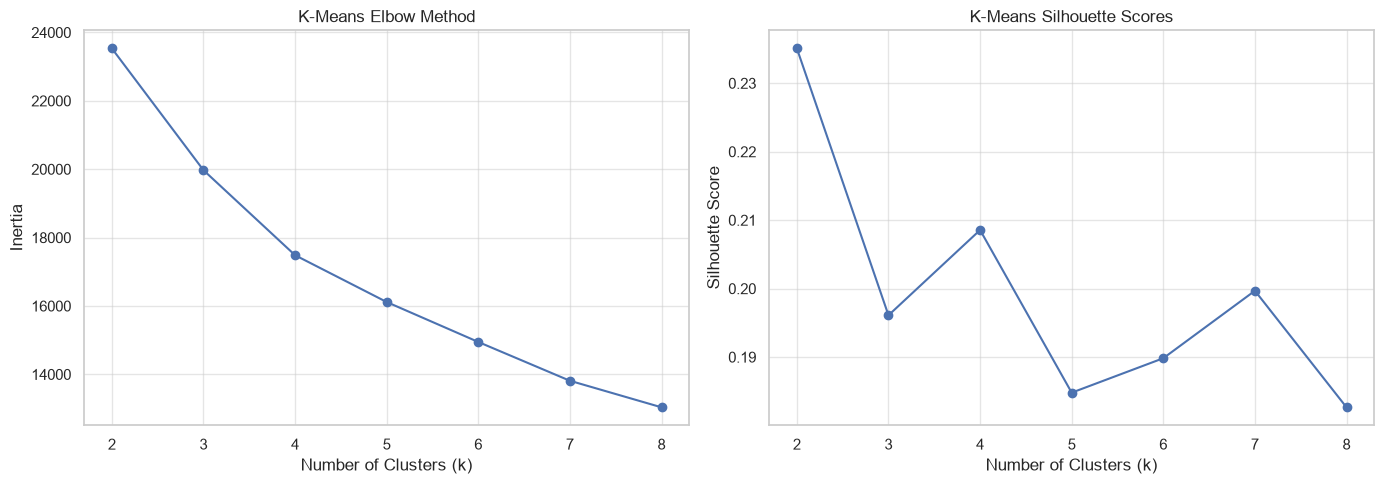

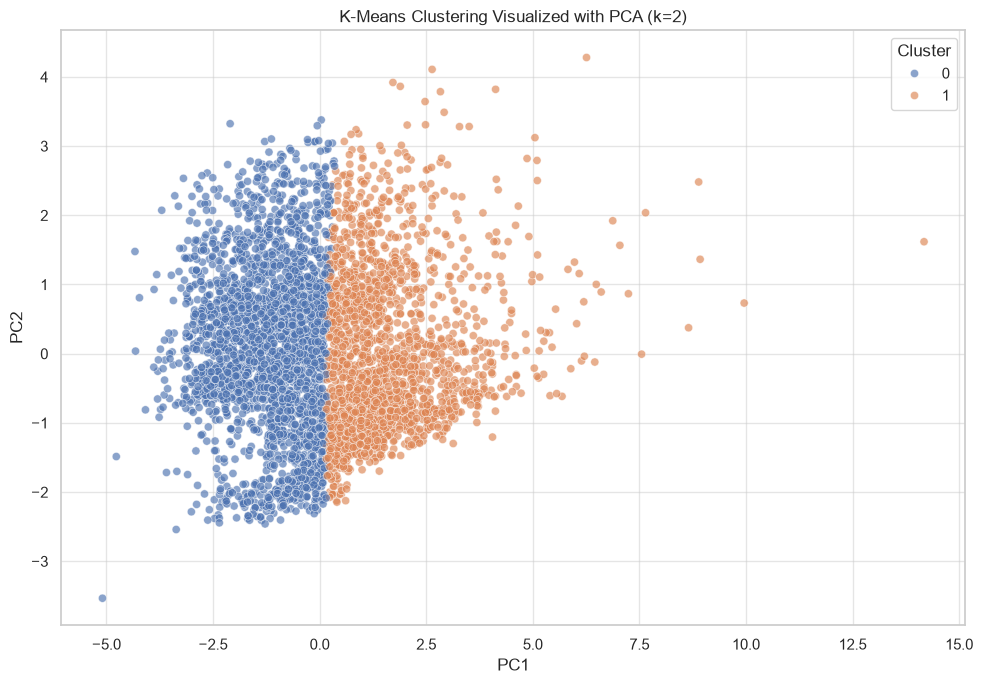

K-Means clustering completed.


In [60]:

# K-MEANS CLUSTERING


cluster_features = [
    "log_price",
    "sqft_living",
    "log_sqft_lot",
    "bathrooms",
    "bedrooms",
    "house_age_at_sale",
    "condition"
]

cluster_data = (
    phase2_df[cluster_features]
    .replace([np.inf, -np.inf], np.nan)
)

# Only use complete observations for clustering
cluster_index = cluster_data.dropna().index

X_cluster = cluster_data.loc[cluster_index].copy()

# Standardization is necessary because variables use
# different measurement scales.
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)



# Determine suitable number of clusters


k_results = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    silhouette = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(2000, len(X_scaled)),
        random_state=42
    )

    k_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": silhouette
    })

kmeans_scores = pd.DataFrame(k_results)

print("K-Means Model Selection")
display(kmeans_scores.round(5))

kmeans_scores.to_csv(
    PHASE2_DIR / "kmeans_model_selection.csv",
    index=False
)

best_k = int(
    kmeans_scores.loc[
        kmeans_scores["silhouette_score"].idxmax(),
        "k"
    ]
)

print("Selected number of clusters:", best_k)



# Final K-Means model


best_kmeans = KMeans(
    n_clusters=best_k,
    n_init=50,
    random_state=42
)

kmeans_labels = best_kmeans.fit_predict(
    X_scaled
)

phase2_df["kmeans_cluster"] = pd.Series(
    pd.NA,
    index=phase2_df.index,
    dtype="Int64"
)

phase2_df.loc[
    cluster_index,
    "kmeans_cluster"
] = kmeans_labels


# K-Means cluster profiles


profile_features = [
    "price",
    "sqft_living",
    "sqft_lot",
    "bedrooms",
    "bathrooms",
    "house_age_at_sale",
    "condition"
]

kmeans_profile = (
    phase2_df
    .loc[cluster_index]
    .groupby("kmeans_cluster")[profile_features]
    .mean()
)

kmeans_counts = (
    phase2_df
    .loc[cluster_index]
    .groupby("kmeans_cluster")
    .size()
)

kmeans_profile.insert(
    0,
    "number_of_houses",
    kmeans_counts
)

print("\nK-Means Cluster Profiles")
display(kmeans_profile.round(2))

kmeans_profile.to_csv(
    PHASE2_DIR / "kmeans_cluster_profiles.csv"
)


# Elbow + silhouette plots


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    kmeans_scores["k"],
    kmeans_scores["inertia"],
    marker="o"
)

axes[0].set_title("K-Means Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    kmeans_scores["k"],
    kmeans_scores["silhouette_score"],
    marker="o"
)

axes[1].set_title("K-Means Silhouette Scores")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "kmeans_model_selection.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# PCA visualization of K-Means clusters


pca = PCA(n_components=2)

X_pca = pca.fit_transform(
    X_scaled
)

kmeans_pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": kmeans_labels.astype(str)
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=kmeans_pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    alpha=0.65,
    s=35
)

plt.title(
    f"K-Means Clustering Visualized with PCA (k={best_k})"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "kmeans_clusters_pca.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("K-Means clustering completed.")

Hierarchical Clustering Silhouette Score: 0.1937

Hierarchical Cluster Profiles


,number_of_houses,price,sqft_living,sqft_lot,bedrooms,bathrooms,house_age_at_sale,condition
hierarchical_cluster,,,,,,,,
0,2566,"680,161.58","2,569.00","19,222.65",3.68,2.58,28.12,3.22
1,1985,"399,866.57","1,567.95","9,163.75",3.03,1.60,62.70,3.75


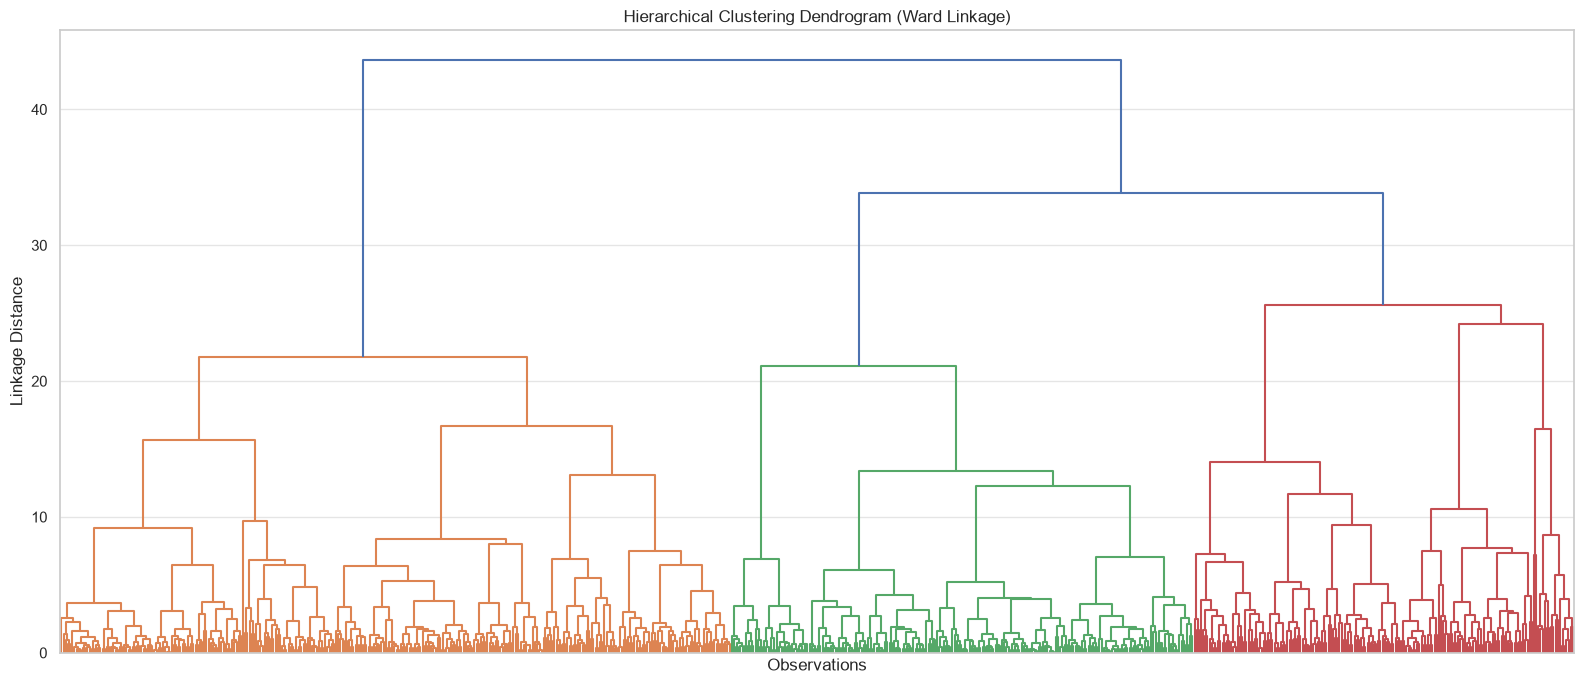

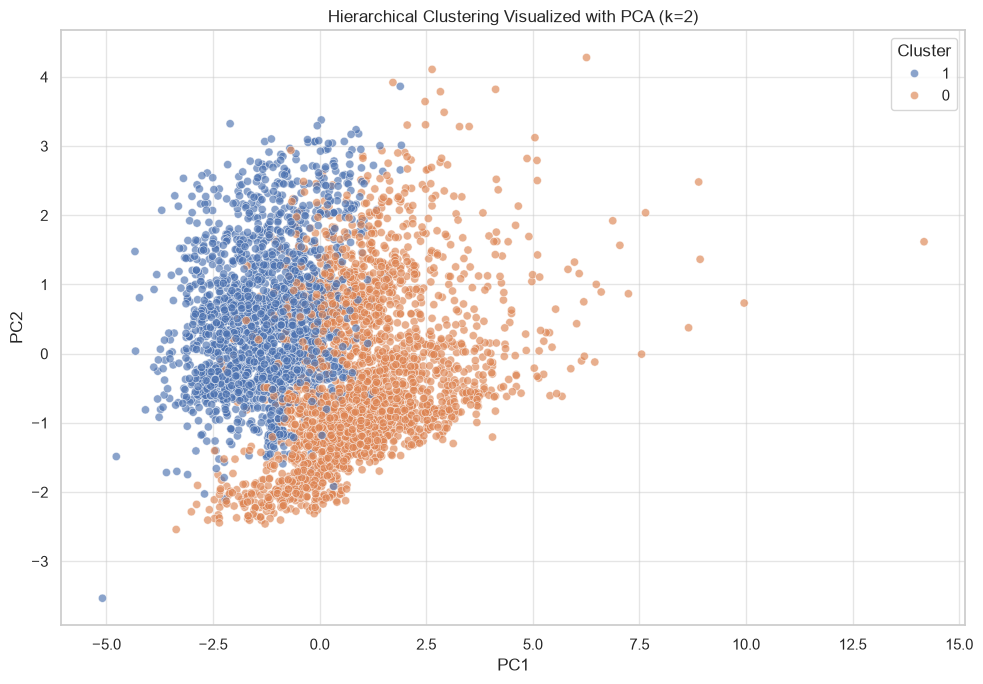


K-Means vs Hierarchical Cluster Assignment


Hierarchical Cluster,0,1
K-Means Cluster,,
0,754,1832
1,1812,153


Hierarchical clustering completed.


In [61]:

# HIERARCHICAL CLUSTERING


# Use the selected K-Means k so both clustering techniques
# can be compared using the same number of clusters.

hierarchical_model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(
    X_scaled
)

phase2_df["hierarchical_cluster"] = pd.Series(
    pd.NA,
    index=phase2_df.index,
    dtype="Int64"
)

phase2_df.loc[
    cluster_index,
    "hierarchical_cluster"
] = hierarchical_labels



# Hierarchical silhouette score


hierarchical_silhouette = silhouette_score(
    X_scaled,
    hierarchical_labels,
    sample_size=min(2000, len(X_scaled)),
    random_state=42
)

print(
    "Hierarchical Clustering Silhouette Score:",
    round(hierarchical_silhouette, 5)
)


# Hierarchical cluster profiles


hierarchical_profile = (
    phase2_df
    .loc[cluster_index]
    .groupby("hierarchical_cluster")[profile_features]
    .mean()
)

hierarchical_counts = (
    phase2_df
    .loc[cluster_index]
    .groupby("hierarchical_cluster")
    .size()
)

hierarchical_profile.insert(
    0,
    "number_of_houses",
    hierarchical_counts
)

print("\nHierarchical Cluster Profiles")
display(hierarchical_profile.round(2))

hierarchical_profile.to_csv(
    PHASE2_DIR / "hierarchical_cluster_profiles.csv"
)



# Dendrogram
# A representative sample is used only for the dendrogram
# because plotting thousands of leaves would be unreadable.
# The actual clustering above still uses the full dataset.

rng = np.random.default_rng(42)

dendrogram_sample_size = min(
    700,
    len(X_scaled)
)

sample_positions = rng.choice(
    len(X_scaled),
    size=dendrogram_sample_size,
    replace=False
)

linkage_matrix = linkage(
    X_scaled[sample_positions],
    method="ward"
)

plt.figure(figsize=(16, 7))

dendrogram(
    linkage_matrix,
    no_labels=True,
    leaf_rotation=90
)

plt.title(
    "Hierarchical Clustering Dendrogram (Ward Linkage)"
)

plt.xlabel("Observations")
plt.ylabel("Linkage Distance")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "hierarchical_dendrogram.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



# PCA visualization of hierarchical clusters


hierarchical_pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": hierarchical_labels.astype(str)
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=hierarchical_pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    alpha=0.65,
    s=35
)

plt.title(
    f"Hierarchical Clustering Visualized with PCA "
    f"(k={best_k})"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "hierarchical_clusters_pca.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



# Compare K-Means and Hierarchical assignments


cluster_comparison = pd.crosstab(
    phase2_df.loc[
        cluster_index,
        "kmeans_cluster"
    ],
    phase2_df.loc[
        cluster_index,
        "hierarchical_cluster"
    ],
    rownames=["K-Means Cluster"],
    colnames=["Hierarchical Cluster"]
)

print("\nK-Means vs Hierarchical Cluster Assignment")
display(cluster_comparison)

cluster_comparison.to_csv(
    PHASE2_DIR / "clustering_comparison.csv"
)

print("Hierarchical clustering completed.")

In [62]:

# PHASE II FINAL OUTPUT AND VALIDATION


# Export the dataset including clustering results
phase2_df.to_csv(
    PHASE2_DIR / "house_price_phase2_complete.csv",
    index=False
)


validation_checks = {
    "1D numerical statistics completed":
        not one_d_numeric.empty,

    "1D categorical statistics completed":
        not one_d_categorical.empty,

    "2D Pearson correlation completed":
        not pearson_matrix.empty,

    "2D Spearman correlation completed":
        not spearman_matrix.empty,

    "2D covariance completed":
        not covariance_matrix.empty,

    "2D pairwise statistical analysis completed":
        not pairwise_price_stats.empty,

    "3D multiple regression completed":
        len(three_d_regression) >= 1,

    "3D partial correlation completed":
        len(partial_results) >= 1,

    "K-Means clustering completed":
        phase2_df["kmeans_cluster"].notna().any(),

    "Hierarchical clustering completed":
        phase2_df["hierarchical_cluster"].notna().any(),

    "K-Means has multiple clusters":
        phase2_df["kmeans_cluster"].nunique() >= 2,

    "Hierarchical clustering has multiple clusters":
        phase2_df["hierarchical_cluster"].nunique() >= 2
}


validation = pd.DataFrame({
    "Requirement": validation_checks.keys(),
    "Status": [
        "PASS" if value else "FAIL"
        for value in validation_checks.values()
    ]
})

print("=" * 70)
print("PHASE II FINAL VALIDATION")
print("=" * 70)

display(validation)

validation.to_csv(
    PHASE2_DIR / "phase2_validation_summary.csv",
    index=False
)


print("\nSelected K for clustering:", best_k)

print(
    "Best K-Means silhouette score:",
    round(
        kmeans_scores["silhouette_score"].max(),
        5
    )
)

print(
    "Hierarchical silhouette score:",
    round(
        hierarchical_silhouette,
        5
    )
)

print("\nGenerated Phase II files:")

for path in sorted(
    PHASE2_DIR.rglob("*")
):
    if path.is_file():
        print(" -", path)


assert all(validation_checks.values()), \
    "One or more Phase II validation checks failed."


print("\n" + "=" * 70)
print("PHASE II COMPLETED SUCCESSFULLY")
print("=" * 70)

PHASE II FINAL VALIDATION


,Requirement,Status
0,1D numerical statistics completed,PASS
1,1D categorical statistics completed,PASS
2,2D Pearson correlation completed,PASS
3,2D Spearman correlation completed,PASS
4,2D covariance completed,PASS
5,2D pairwise statistical analysis completed,PASS
6,3D multiple regression completed,PASS
7,3D partial correlation completed,PASS
8,K-Means clustering completed,PASS
9,Hierarchical clustering completed,PASS



Selected K for clustering: 2
Best K-Means silhouette score: 0.23508
Hierarchical silhouette score: 0.1937

Generated Phase II files:
 - phase2_outputs\1d_categorical_statistics.csv
 - phase2_outputs\1d_numerical_statistics.csv
 - phase2_outputs\2d_categorical_association_tests.csv
 - phase2_outputs\2d_covariance_matrix.csv
 - phase2_outputs\2d_pearson_correlation_matrix.csv
 - phase2_outputs\2d_price_by_bedroom_group.csv
 - phase2_outputs\2d_price_by_city.csv
 - phase2_outputs\2d_price_by_condition.csv
 - phase2_outputs\2d_price_by_has_basement.csv
 - phase2_outputs\2d_price_by_renovated.csv
 - phase2_outputs\2d_price_by_waterfront.csv
 - phase2_outputs\2d_price_pairwise_statistics.csv
 - phase2_outputs\2d_spearman_correlation_matrix.csv
 - phase2_outputs\3d_multiple_regression_results.csv
 - phase2_outputs\3d_partial_correlations.csv
 - phase2_outputs\clustering_comparison.csv
 - phase2_outputs\figures\1d_statistical_analysis.png
 - phase2_outputs\figures\2d_correlation_heatmap.png
 